# Pull × Air Quadrant Model — Final

End-to-end notebook reflecting the architectural conclusion from the EDA:
*Pull only* and *Air only* are direction extremes; *Both* and *Neither* are
**mixtures** of those patterns differing in intensity. Separate `is_pull` and
`is_air` marginals predicted from the same geometry features ended up as
near-mirror images of each other (corr ≈ −0.80), so their product was a poor
ranker. We drop the marginal-cross architecture entirely.

**Two parallel deliverables**

- **Approach A — Multinomial quadrant classifier.** Predicts P(Neither),
  P(Pull only), P(Air only), P(Both) jointly. Softmax handles the mixture
  cells naturally. Assignment is argmax. Used to *label* hitters.
- **Approach B — Direct joint regression.** Predicts `pull_air_pct` as a
  continuous score. Used to *rank* hitters. Beats the marginal cross on
  Spearman because the regressor absorbs the dependence inside its
  nonlinearity rather than fighting two anti-correlated marginals.

**Other architectural choices**

- Geometry-only modeling. Bat speed and contact depth dropped — swing
  mechanics absorb their predictive signal because mechanics are upstream.
- Handedness enters as `is_L`. Goes into both A and B as a feature.
- Lateral mirror **removed** — the raw `intercept_*_x_inches` is already
  batter-relative in this Statcast vintage.
- Depth sign **flipped** at the source so `+ = out in front of plate`.

**Section 4 contact-plane diagnostics** remain — they're descriptive evidence
for the depth-by-quadrant development story, not model inputs.

## 1. Imports & Config

In [47]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             cohen_kappa_score, accuracy_score)

pd.set_option("display.float_format", "{:.4f}".format)

SEED     = 42
MIN_BBE  = 300
CV_FOLDS = 5

GEO_FEATURES = [
    "mean_tilt", "mean_aa", "mean_dir",
    "z_swing_pct", "o_swing_pct", "fb_swing_share", "mean_length"
]
ALL_FEATURES = GEO_FEATURES + ["is_L"]

QUAD_COLORS = {
    "Neither":           "#FF8C00",
    "Pull only":         "#c44e52",
    "Air only":          "steelblue",
    "Both (Pull + Air)": "green",
}
QUAD_ORDER = ["Neither", "Pull only", "Air only", "Both (Pull + Air)"]

print("Imports OK")


Imports OK


## 2. Load Data and Build Contact-Point Features

Expects `batter_df.parquet` and `bbe_df.parquet` (or in-memory `c_all`).
Contact-point features are built for Section 4 diagnostics only.

In [71]:
# Load batter-level frame
batter_df = pd.read_parquet("batter_df.parquet")
print(f"batter_df loaded: {batter_df.shape}")

batter_df = batter_df[batter_df["n_bbe"] >= MIN_BBE].reset_index(drop=True)
print(f"After BBE filter (≥{MIN_BBE}): {len(batter_df)} hitters")

# Load BBE-level frame for contact-plane diagnostics
try:
    bbe = pd.read_parquet("bbe_df.parquet")
    print(f"bbe_df loaded: {bbe.shape}")
except FileNotFoundError:
    bbe = c_all
    print(f"Using in-memory c_all: {bbe.shape}")

# spray_angle_norm sign is inverted at the source, AND pull should be defined
# by the ±15° cutoff (Pull/Center/Oppo), not a bare sign check at 0.
PULL_CUTOFF = 15
if "pull_air" not in bbe.columns:
    bbe["pull_air"] = ((bbe["spray_angle_norm"] < -PULL_CUTOFF) &   # true Pull zone
                       (bbe["launch_angle"]     >= 10)).astype(int)

# ── Sanity check: does batter_df's OWN pull_pct carry the same inversion? ───
# This matters a lot — if yes, every is_pull/quadrant label built earlier in
# this project has Pull and Oppo swapped, not just this local bbe['pull_air'].
if "pull_pct" in batter_df.columns:
    check_pull = ((bbe["spray_angle_norm"] < 0).groupby(bbe["batter"]).mean()
                 .rename("recomputed_pull_pct"))
    cmp = batter_df[["batter", "pull_pct"]].merge(
        check_pull, on="batter", how="inner")
    diff = (cmp["pull_pct"] - cmp["recomputed_pull_pct"]).abs()
    print(f"\n── Checking batter_df['pull_pct'] against corrected recomputation ──")
    print(f"  mean |difference|: {diff.mean():.4f}")
    print(f"  hitters matching within 0.02: {(diff < 0.02).mean():.1%}")
    if diff.mean() < 0.02:
        print("  → batter_df['pull_pct'] ALREADY uses the correct sign — only")
        print("    this local bbe['pull_air'] needed the flip. No further action.")
    else:
        print("  → batter_df['pull_pct'] appears to carry the SAME inversion —")
        print("    every is_pull / quadrant label built earlier in this project")
        print("    likely has Pull and Oppo swapped. This needs fixing at the")
        print("    source (wherever batter_df.parquet's pull_pct was built) and")
        print("    the full modeling pipeline re-run, not just this cell.")


batter_df loaded: (497, 22)
After BBE filter (≥300): 442 hitters
bbe_df loaded: (390953, 124)

── Checking batter_df['pull_pct'] against corrected recomputation ──
  mean |difference|: 0.1926
  hitters matching within 0.02: 2.7%
  → batter_df['pull_pct'] appears to carry the SAME inversion —
    every is_pull / quadrant label built earlier in this project
    likely has Pull and Oppo swapped. This needs fixing at the
    source (wherever batter_df.parquet's pull_pct was built) and
    the full modeling pipeline re-run, not just this cell.


In [72]:
# Build 3D contact-point features at the BBE level (Section 4 only)
X_COL = "intercept_ball_minus_batter_pos_x_inches"
Y_COL = "intercept_ball_minus_batter_pos_y_inches"
Z_COL = "intercept_ball_minus_batter_pos_z_inches"

cp_cols = [c for c in [X_COL, Y_COL, Z_COL] if c in bbe.columns]
cp = bbe.dropna(subset=cp_cols + ["stand", "batter", "pull_air"]).copy()

# Lateral: NO mirror (raw column is already batter-relative)
if X_COL in cp.columns:
    cp["x_in"]      = cp[X_COL]
cp["depth_in"]      = -cp[Y_COL]                 # sign flip
if Z_COL in cp.columns:
    cp["height_in"] = cp[Z_COL]

# Within-hitter centering for the F1/F2 panels
for col in [c for c in ["x_in", "depth_in", "height_in"] if c in cp.columns]:
    cp[col + "_c"] = cp.groupby("batter")[col].transform(lambda s: s - s.mean())

# Sanity checks
if "bat_speed" in cp.columns:
    r = cp[["depth_in", "bat_speed"]].dropna().corr().iloc[0, 1]
    print(f"corr(depth_in, bat_speed) = {r:+.3f}   (expect + if depth sign is right)")
print(f"\nLateral mean by handedness (no mirror — should be similar for L and R):")
for s in ["R", "L"]:
    m = cp["stand"] == s
    print(f"  {s}HB: x_in mean = {cp.loc[m, 'x_in'].mean():+.2f}\"  (n={m.sum():,})")


corr(depth_in, bat_speed) = -0.241   (expect + if depth sign is right)

Lateral mean by handedness (no mirror — should be similar for L and R):
  RHB: x_in mean = +37.04"  (n=166,296)
  LHB: x_in mean = +36.87"  (n=123,408)


## 3. Quadrant Assignment

In [73]:
pull_cut = batter_df["pull_pct"].median()
air_cut  = batter_df["air_ball_pct"].median()

batter_df["is_pull"] = (batter_df["pull_pct"]     >= pull_cut).astype(int)
batter_df["is_air"]  = (batter_df["air_ball_pct"] >= air_cut ).astype(int)
batter_df["is_L"]    = (batter_df["stand"]        == "L").astype(int)

def _label(r):
    p, a = r["is_pull"], r["is_air"]
    if p and a:      return "Both (Pull + Air)"
    if p and not a:  return "Pull only"
    if not p and a:  return "Air only"
    return "Neither"
batter_df["quadrant"] = batter_df.apply(_label, axis=1)

print(f"Cutoffs: pull% = {pull_cut:.3f},  air% = {air_cut:.3f}\n")
print("Quadrant counts (overall):")
print(batter_df["quadrant"].value_counts().reindex(QUAD_ORDER).to_string())
print("\nQuadrant counts by handedness:")
print(pd.crosstab(batter_df["stand"], batter_df["quadrant"])
      .reindex(columns=QUAD_ORDER).to_string())


Cutoffs: pull% = 0.403,  air% = 0.561

Quadrant counts (overall):
quadrant
Neither               82
Pull only            139
Air only             139
Both (Pull + Air)     82

Quadrant counts by handedness:
quadrant  Neither  Pull only  Air only  Both (Pull + Air)
stand                                                    
L              41         49        64                 27
R              41         90        75                 55


── Correlations (Pearson / Spearman) at the batter level ──────────────
                       pair  pearson  spearman
    pull_pct × air_ball_pct  -0.4820   -0.4580
    pull_pct × pull_air_pct   0.5550    0.5540
air_ball_pct × pull_air_pct   0.3290    0.3160

── Correlation of each marginal with Pull Air%, by quadrant ───────────
         quadrant   n  pull → pull_air  air  → pull_air  pull × air
          Neither  82           0.5790           0.3750     -0.2910
        Pull only 139           0.2840           0.5820     -0.3460
         Air only 139           0.7680           0.0950     -0.2840
Both (Pull + Air)  82           0.5570           0.5350     -0.1530


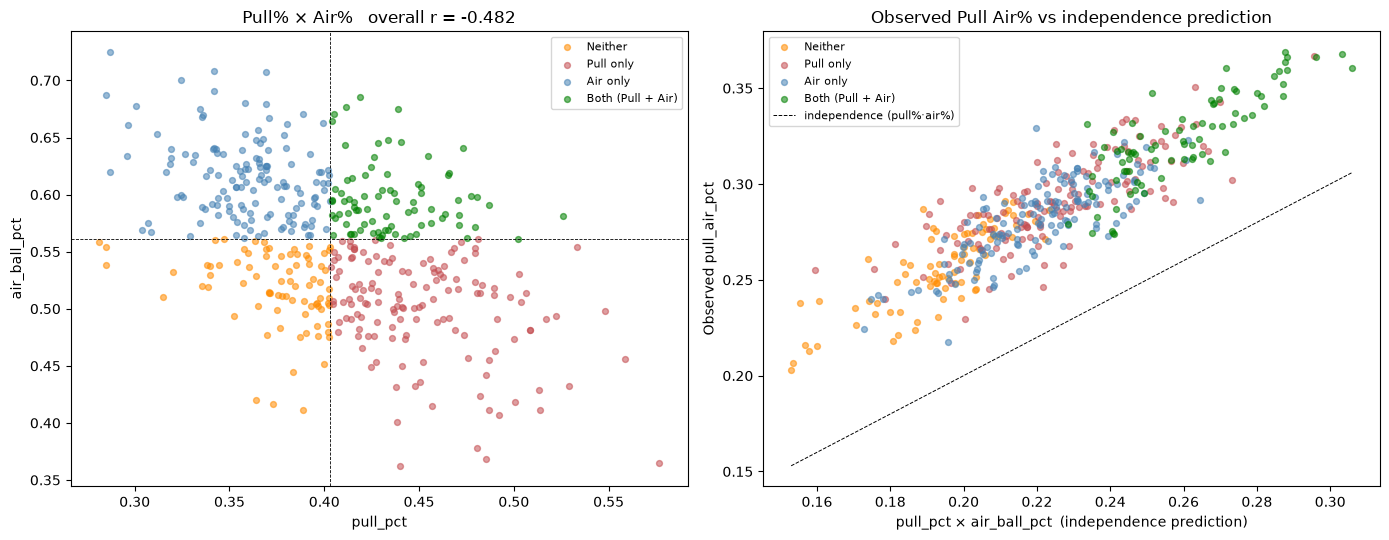


Dependence factor  D = pull_air% / (pull%·air%):
  overall mean D = 1.288   median = 1.284   (1.0 = independence, <1 = trade-off)

Mean D by quadrant:
quadrant
Neither             1.3240
Pull only           1.2980
Air only            1.2790
Both (Pull + Air)   1.2480


In [74]:
# ── 3.5  Batter-level correlations among the marginals and the joint ────────
print("── Correlations (Pearson / Spearman) at the batter level ──────────────")
pairs = [("pull_pct", "air_ball_pct"), ("pull_pct", "pull_air_pct"),
         ("air_ball_pct", "pull_air_pct")]
rows = []
for a, b in pairs:
    r_p = pearsonr(batter_df[a],  batter_df[b])[0]
    r_s = spearmanr(batter_df[a], batter_df[b]).correlation
    rows.append({"pair": f"{a} × {b}", "pearson": r_p, "spearman": r_s})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Correlations by quadrant — do the marginals relate to Pull Air% differently
# for direction wedges vs magnitude corners?
print("\n── Correlation of each marginal with Pull Air%, by quadrant ───────────")
qc_rows = []
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    sub_q = batter_df.loc[m]
    if len(sub_q) < 20: continue
    qc_rows.append({
        "quadrant":         q,
        "n":                m.sum(),
        "pull → pull_air":  pearsonr(sub_q["pull_pct"],     sub_q["pull_air_pct"])[0],
        "air  → pull_air":  pearsonr(sub_q["air_ball_pct"], sub_q["pull_air_pct"])[0],
        "pull × air":       pearsonr(sub_q["pull_pct"],     sub_q["air_ball_pct"])[0],
    })
print(pd.DataFrame(qc_rows).round(3).to_string(index=False))

# Visualise the joint distribution of pull% and air% coloured by quadrant
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Pull% vs Air% scatter
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    axes[0].scatter(batter_df.loc[m, "pull_pct"], batter_df.loc[m, "air_ball_pct"],
                    s=18, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[0].axvline(batter_df["pull_pct"].median(),     color="black", ls="--", lw=0.6)
axes[0].axhline(batter_df["air_ball_pct"].median(), color="black", ls="--", lw=0.6)
axes[0].set_xlabel("pull_pct"); axes[0].set_ylabel("air_ball_pct")
axes[0].set_title(f"Pull% × Air%   overall r = "
                  f"{pearsonr(batter_df['pull_pct'], batter_df['air_ball_pct'])[0]:+.3f}")
axes[0].legend(fontsize=8)

# (b) Contribution to Pull Air%: pull%·air% vs observed pull_air_pct
prod = batter_df["pull_pct"] * batter_df["air_ball_pct"]
for q in QUAD_ORDER:
    m = batter_df["quadrant"] == q
    axes[1].scatter(prod[m], batter_df.loc[m, "pull_air_pct"],
                    s=18, alpha=0.55, color=QUAD_COLORS[q], label=q)
lo, hi = prod.min(), prod.max()
axes[1].plot([lo, hi], [lo, hi], "k--", lw=0.7, label="independence (pull%·air%)")
axes[1].set_xlabel("pull_pct × air_ball_pct  (independence prediction)")
axes[1].set_ylabel("Observed pull_air_pct")
axes[1].set_title("Observed Pull Air% vs independence prediction")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Dependence factor D = observed / independence
D = batter_df["pull_air_pct"] / (batter_df["pull_pct"] * batter_df["air_ball_pct"])
print(f"\nDependence factor  D = pull_air% / (pull%·air%):")
print(f"  overall mean D = {D.mean():.3f}   median = {D.median():.3f}   "
      f"(1.0 = independence, <1 = trade-off)")
print(f"\nMean D by quadrant:")
print(batter_df.assign(D=D).groupby("quadrant")["D"]
      .mean().reindex(QUAD_ORDER).round(3).to_string())

## 4. Contact-Plane Diagnostics by Quadrant

Descriptive maps for the depth-by-quadrant development story. Not model input.
The F2 panel is the informative one — where each quadrant out- or
under-performs the overall pull-air contact map.

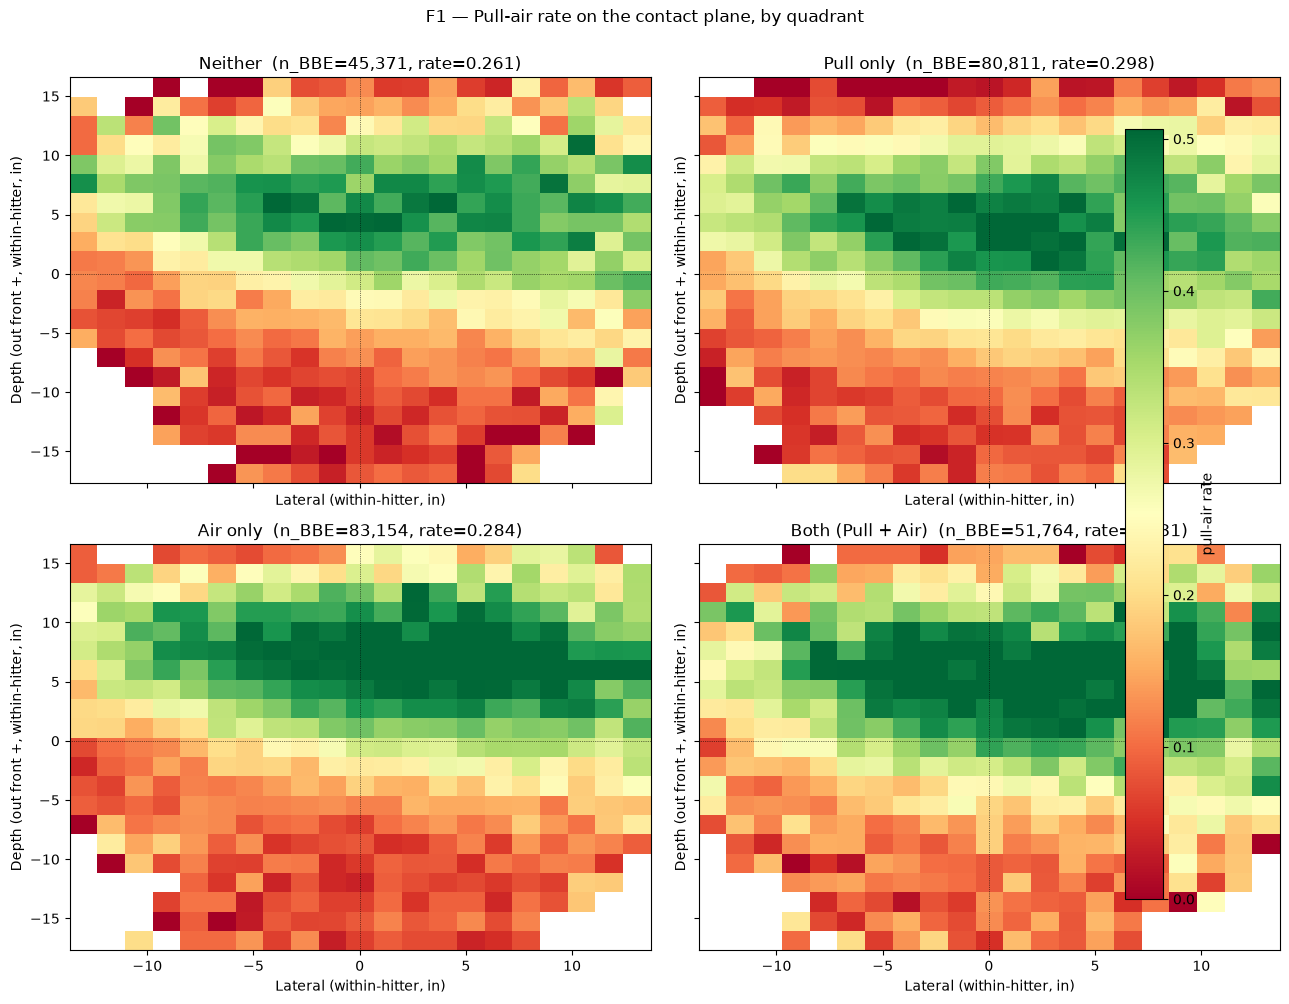

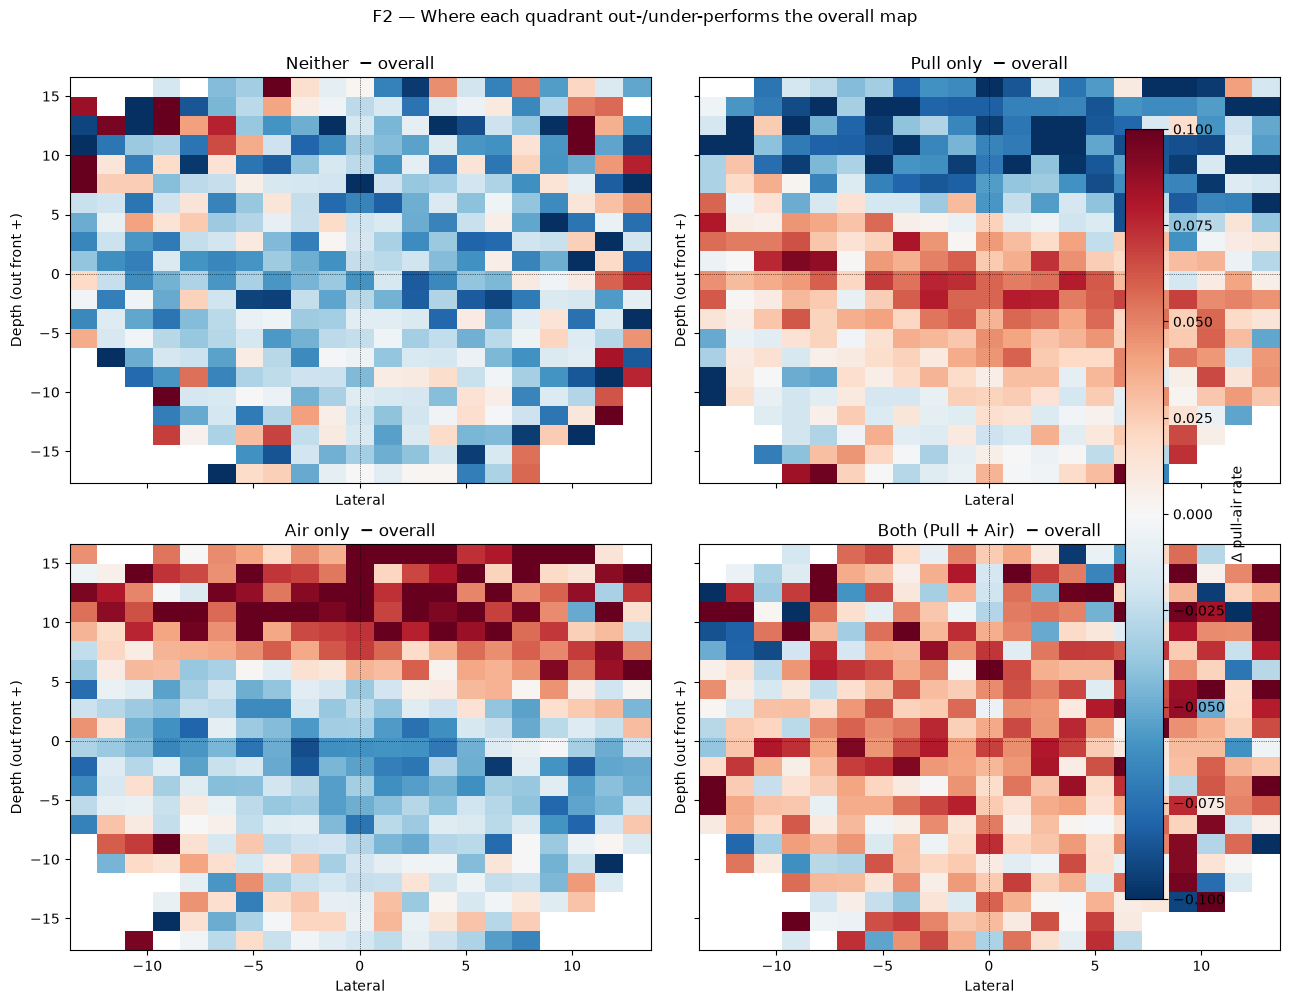

In [75]:
within_q = cp.merge(batter_df[["batter", "quadrant"]], on="batter", how="left")
within_q = within_q.dropna(subset=["quadrant", "x_in_c", "depth_in_c", "pull_air"])

def _heat(x, y, z, xe, ye, floor=10):
    h_count, _, _ = np.histogram2d(x, y, bins=[xe, ye])
    h_sum,   _, _ = np.histogram2d(x, y, bins=[xe, ye], weights=z)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(h_count >= floor, h_sum / h_count, np.nan)

xb = np.linspace(within_q["x_in_c"].quantile(0.01),
                 within_q["x_in_c"].quantile(0.99), 22)
yb = np.linspace(within_q["depth_in_c"].quantile(0.01),
                 within_q["depth_in_c"].quantile(0.99), 22)
overall_rate = _heat(within_q["x_in_c"].values, within_q["depth_in_c"].values,
                     within_q["pull_air"].values, xb, yb)
vmax = float(np.nanpercentile(overall_rate, 98))

# F1 — raw per-quadrant heatmaps (shared color scale)
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, q in zip(axes.flat, QUAD_ORDER):
    sub_q = within_q[within_q["quadrant"] == q]
    rate  = _heat(sub_q["x_in_c"].values, sub_q["depth_in_c"].values,
                  sub_q["pull_air"].values, xb, yb)
    im = ax.imshow(rate.T, origin="lower", aspect="auto", cmap="RdYlGn",
                   extent=[xb[0], xb[-1], yb[0], yb[-1]], vmin=0, vmax=vmax)
    ax.axvline(0, color="black", lw=0.5, ls=":")
    ax.axhline(0, color="black", lw=0.5, ls=":")
    ax.set_title(f"{q}  (n_BBE={len(sub_q):,}, rate={sub_q['pull_air'].mean():.3f})")
    ax.set_xlabel("Lateral (within-hitter, in)")
    ax.set_ylabel("Depth (out front +, within-hitter, in)")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.04, label="pull-air rate")
plt.suptitle("F1 — Pull-air rate on the contact plane, by quadrant", y=1.00)
plt.tight_layout(); plt.show()

# F2 — Δ vs overall
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, q in zip(axes.flat, QUAD_ORDER):
    sub_q = within_q[within_q["quadrant"] == q]
    rate  = _heat(sub_q["x_in_c"].values, sub_q["depth_in_c"].values,
                  sub_q["pull_air"].values, xb, yb)
    diff  = rate - overall_rate
    im = ax.imshow(diff.T, origin="lower", aspect="auto", cmap="RdBu_r",
                   extent=[xb[0], xb[-1], yb[0], yb[-1]], vmin=-0.10, vmax=0.10)
    ax.axvline(0, color="black", lw=0.5, ls=":")
    ax.axhline(0, color="black", lw=0.5, ls=":")
    ax.set_title(f"{q}  − overall")
    ax.set_xlabel("Lateral"); ax.set_ylabel("Depth (out front +)")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.04, label="Δ pull-air rate")
plt.suptitle("F2 — Where each quadrant out-/under-performs the overall map", y=1.00)
plt.tight_layout(); plt.show()


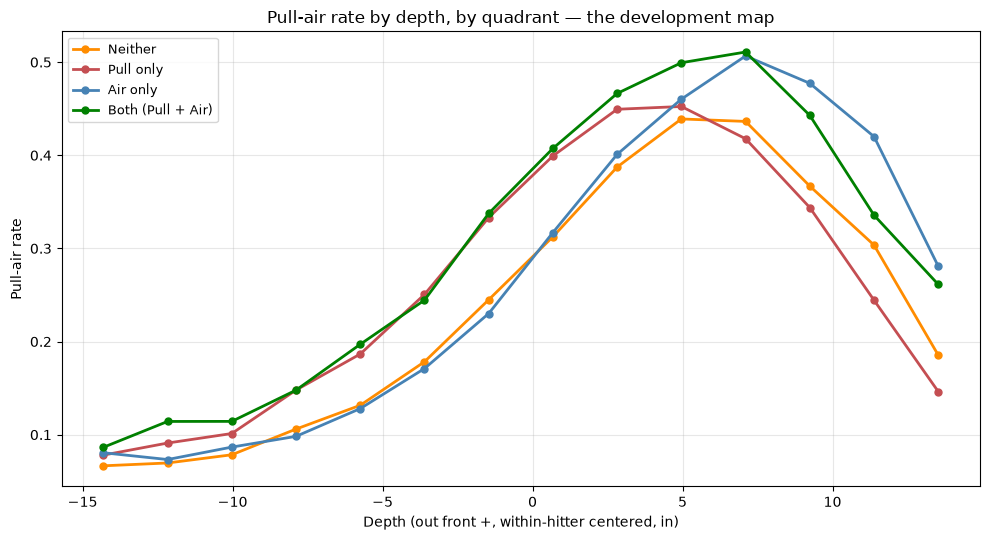

Read: at every depth, ranking from most to least pull-air is Both > Pull/Air > Neither.
Each quadrant's peak location is its development target.


In [76]:
# 1D depth profile by quadrant — the cleaner view given F2's horizontal bands
fig, ax = plt.subplots(figsize=(10, 5.5))
depth_bins = np.linspace(within_q["depth_in_c"].quantile(0.02),
                         within_q["depth_in_c"].quantile(0.98), 15)
for q in QUAD_ORDER:
    sub_q = within_q[within_q["quadrant"] == q].copy()
    sub_q["_bin"] = pd.cut(sub_q["depth_in_c"], depth_bins)
    grp = sub_q.groupby("_bin", observed=True)["pull_air"].agg(["mean", "count"])
    grp = grp[grp["count"] >= 30]
    centers = [iv.mid for iv in grp.index]
    ax.plot(centers, grp["mean"], "o-", color=QUAD_COLORS[q], lw=2,
            markersize=5, label=q)
ax.set_xlabel("Depth (out front +, within-hitter centered, in)")
ax.set_ylabel("Pull-air rate")
ax.set_title("Pull-air rate by depth, by quadrant — the development map")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Read: at every depth, ranking from most to least pull-air is Both > Pull/Air > Neither.")
print("Each quadrant's peak location is its development target.")


In [77]:
# ── Depth-informed features from the POOLED (not quadrant-specific) curve ──
# Avoids circularity: uses one population-level depth→rate curve, not the
# per-quadrant curves shown in the chart.

# 1. Fit the pooled depth → pull-air rate curve on ALL BBEs (no quadrant split)
depth_bins_fit = np.linspace(cp["depth_in_c"].quantile(0.01),
                             cp["depth_in_c"].quantile(0.99), 30)
cp["_depth_bin"] = pd.cut(cp["depth_in_c"], depth_bins_fit)
pooled_curve = (cp.groupby("_depth_bin", observed=True)["pull_air"]
                .agg(["mean", "count"]))
pooled_curve = pooled_curve[pooled_curve["count"] >= 50]
bin_centers  = np.array([iv.mid for iv in pooled_curve.index])
bin_rates    = pooled_curve["mean"].values

# 2. Feature A — "depth-implied pull-air rate": for each hitter, interpolate
#    the pooled curve at their own BBE depths and average. This is a
#    NONLINEAR transform that respects the inverted-U shape, unlike mean_depth.
from numpy import interp
cp["_depth_implied_rate"] = interp(cp["depth_in_c"], bin_centers, bin_rates)
depth_implied = (cp.groupby("batter")["_depth_implied_rate"]
                 .mean().rename("depth_implied_rate").reset_index())

# 3. Feature B — "% of contact in the optimal window": share of BBE with
#    depth in the region where quadrants actually separate (from the chart:
#    roughly 0 to +10). This targets the discriminative zone directly instead
#    of averaging over the flat, uninformative region below 0.
OPT_LO, OPT_HI = 0, 10
cp["_in_optimal"] = cp["depth_in_c"].between(OPT_LO, OPT_HI).astype(int)
optimal_share = (cp.groupby("batter")["_in_optimal"]
                 .mean().rename("depth_optimal_share").reset_index())

# ── Construct mean_depth on batter_df from cp's per-BBE depth_in ───────────
depth_agg = (cp.groupby("batter")["depth_in"]
             .mean().rename("mean_depth").reset_index())

if "mean_depth" in batter_df.columns:
    batter_df = batter_df.drop(columns="mean_depth")
batter_df = batter_df.merge(depth_agg, on="batter", how="left")

print(f"mean_depth added: {'mean_depth' in batter_df.columns}")
print(f"non-null: {batter_df['mean_depth'].notna().sum()} of {len(batter_df)}")
print(batter_df["mean_depth"].describe().round(2).to_string())

# Merge onto batter_df
for feat_df in [depth_implied, optimal_share]:
    col = [c for c in feat_df.columns if c != "batter"][0]
    if col in batter_df.columns:
        batter_df = batter_df.drop(columns=col)
    batter_df = batter_df.merge(feat_df, on="batter", how="left")

print("New depth-shape features:")
print(batter_df[["depth_implied_rate", "depth_optimal_share"]].describe().round(3).to_string())

# Quick check: do these correlate with pull_air_pct better than raw mean_depth?
for f in ["mean_depth", "depth_implied_rate", "depth_optimal_share"]:
    r = spearmanr(batter_df[f], batter_df["pull_air_pct"]).correlation
    print(f"  Spearman({f}, pull_air_pct) = {r:+.3f}")

mean_depth added: True
non-null: 442 of 442
count   442.0000
mean    -29.9800
std       3.0400
min     -38.9500
25%     -32.1400
50%     -29.9500
75%     -27.8800
max     -20.8500
New depth-shape features:
       depth_implied_rate  depth_optimal_share
count            442.0000             442.0000
mean               0.2940               0.4290
std                0.0080               0.0270
min                0.2670               0.3390
25%                0.2890               0.4130
50%                0.2940               0.4290
75%                0.2990               0.4470
max                0.3170               0.5010
  Spearman(mean_depth, pull_air_pct) = -0.062
  Spearman(depth_implied_rate, pull_air_pct) = +0.130
  Spearman(depth_optimal_share, pull_air_pct) = +0.153


In [78]:
# ── Reconstruct raw_all from the cached per-season Statcast parquets ───────
from pathlib import Path

DATA_DIR = Path("statcast_data")
SEASONS  = [2023, 2024, 2025]   # adjust to match whatever you originally pulled

season_files = [DATA_DIR / f"statcast_{y}_miss_distance.parquet" for y in SEASONS]
missing = [f for f in season_files if not f.exists()]
if missing:
    print(f"Missing cached files: {missing}")
    print("Available files in statcast_data/:")
    print(list(DATA_DIR.glob("*.parquet")) if DATA_DIR.exists() else "directory not found")
else:
    raw_all = pd.concat([pd.read_parquet(f) for f in season_files], ignore_index=True)
    print(f"raw_all reconstructed: {raw_all.shape}")
    print(f"Seasons: {sorted(pd.to_datetime(raw_all['game_date']).dt.year.unique())}")
    print(f"Columns include 'events': {'events' in raw_all.columns}")
    print(f"Columns include 'description': {'description' in raw_all.columns}")

raw_all reconstructed: (2305081, 119)
Seasons: [np.int32(2023), np.int32(2024), np.int32(2025)]
Columns include 'events': True
Columns include 'description': True


k_pct non-null: 442 of 442
contact_rate non-null: 442 of 442

── Spearman correlations ───────────────────────────────────────────────
target        pull_pct  air_ball_pct  pull_air_pct
predictor                                         
contact_rate    0.2530       -0.1840       -0.0250
k_pct          -0.2300        0.2950        0.1320

── K% and contact rate by quadrant ─────────────────────────────────────
                   k_pct  contact_rate
quadrant                              
Neither           0.2150        0.7670
Pull only         0.2040        0.7860
Air only          0.2410        0.7530
Both (Pull + Air) 0.2230        0.7750


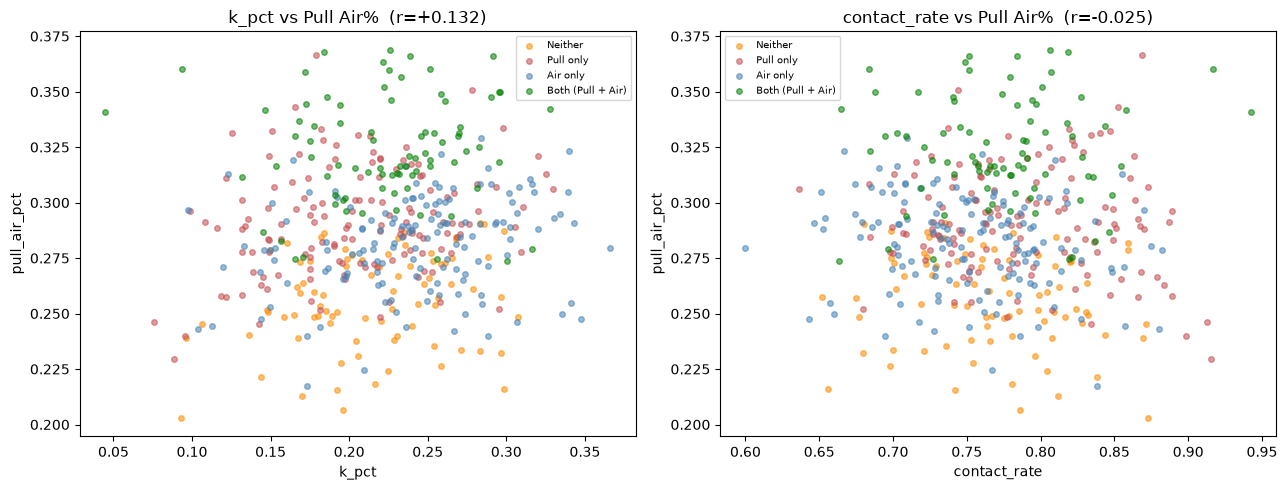

In [79]:
# ── Strikeout rate & contact rate vs Pull%, Air%, Pull Air% ─────────────────

# Build K% and contact rate from pitch-level data if not already present
if "k_pct" not in batter_df.columns or "contact_rate" not in batter_df.columns:
    # Need plate-appearance-level outcomes and swing-level contact/miss
    SWING_DESCS = {"hit_into_play", "swinging_strike", "foul",
                   "swinging_strike_blocked", "foul_tip"}
    WHIFF_DESCS = {"swinging_strike", "swinging_strike_blocked"}

    pitches = raw_all[raw_all["batter"].notna()].copy()
    pitches["is_swing"] = pitches["description"].isin(SWING_DESCS).astype(int)
    pitches["is_whiff"] = pitches["description"].isin(WHIFF_DESCS).astype(int)

    # Contact rate: contact made / swings taken (whiffs excluded from numerator)
    contact_agg = (
        pitches[pitches["is_swing"] == 1]
        .groupby("batter")
        .agg(swings=("is_swing", "count"), whiffs=("is_whiff", "sum"))
        .reset_index()
    )
    contact_agg["contact_rate"] = 1 - (contact_agg["whiffs"] / contact_agg["swings"])

    # K%: strikeouts / plate appearances (using events, one row per PA outcome)
    pa_outcomes = raw_all[raw_all["events"].notna()].copy()
    k_agg = (
        pa_outcomes.groupby("batter")
        .agg(pa=("events", "count"),
             k=("events", lambda s: (s == "strikeout").sum()))
        .reset_index()
    )
    k_agg["k_pct"] = k_agg["k"] / k_agg["pa"]

    batter_df = batter_df.merge(contact_agg[["batter", "contact_rate"]], on="batter", how="left")
    batter_df = batter_df.merge(k_agg[["batter", "k_pct"]], on="batter", how="left")

print(f"k_pct non-null: {batter_df['k_pct'].notna().sum()} of {len(batter_df)}")
print(f"contact_rate non-null: {batter_df['contact_rate'].notna().sum()} of {len(batter_df)}")

# ── Correlations ─────────────────────────────────────────────────────────
targets = ["pull_pct", "air_ball_pct", "pull_air_pct"]
predictors = ["k_pct", "contact_rate"]

print("\n── Spearman correlations ───────────────────────────────────────────────")
rows = []
for p in predictors:
    for t in targets:
        m = batter_df[[p, t]].dropna()
        r = spearmanr(m[p], m[t]).correlation
        rows.append({"predictor": p, "target": t, "spearman": r, "n": len(m)})
corr_df = pd.DataFrame(rows).pivot(index="predictor", columns="target", values="spearman")
print(corr_df[targets].round(3).to_string())

# By quadrant — does K%/contact rate explain the uniform Both-quadrant advantage?
print("\n── K% and contact rate by quadrant ─────────────────────────────────────")
print(batter_df.groupby("quadrant")[["k_pct", "contact_rate"]]
      .mean().reindex(QUAD_ORDER).round(3).to_string())

# Visual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, p in zip(axes, predictors):
    for q in QUAD_ORDER:
        m = batter_df["quadrant"] == q
        ax.scatter(batter_df.loc[m, p], batter_df.loc[m, "pull_air_pct"],
                  s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
    ax.set_xlabel(p); ax.set_ylabel("pull_air_pct")
    r = spearmanr(batter_df[p], batter_df["pull_air_pct"]).correlation
    ax.set_title(f"{p} vs Pull Air%  (r={r:+.3f})")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

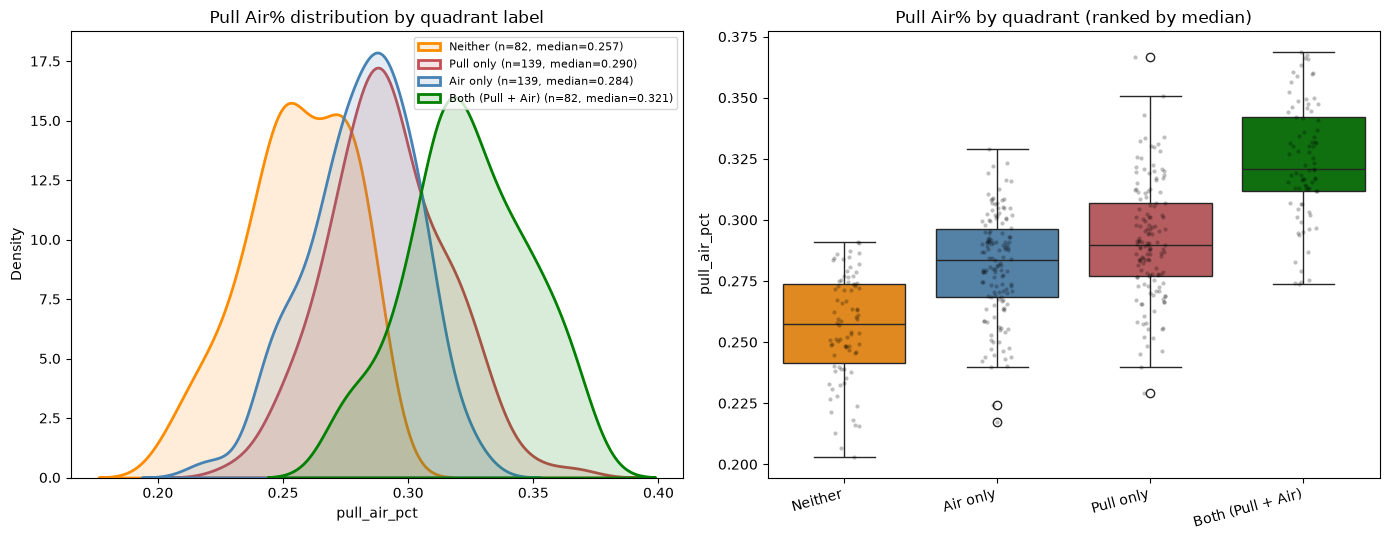

── How much does the quadrant label explain Pull Air%? ────────────────
  ANOVA:   F = 128.32, p = 1.18e-59
  Kruskal: H = 198.30, p = 9.83e-43
  η² (variance explained) = 0.468

Median Pull Air% by quadrant:
quadrant
Neither             0.2573
Pull only           0.2899
Air only            0.2837
Both (Pull + Air)   0.3208

── Pairwise overlap between adjacent quadrants (by median rank) ───────
  Neither vs Air only:
    8/82 (9.8%) of 'Neither' hitters exceed the 'Air only' median
    21/139 (15.1%) of 'Air only' hitters fall below the 'Neither' median
  Air only vs Pull only:
    54/139 (38.8%) of 'Air only' hitters exceed the 'Pull only' median
    50/139 (36.0%) of 'Pull only' hitters fall below the 'Air only' median
  Pull only vs Both (Pull + Air):
    16/139 (11.5%) of 'Pull only' hitters exceed the 'Both (Pull + Air)' median
    7/82 (8.5%) of 'Both (Pull + Air)' hitters fall below the 'Pull only' median

── Hitters within 2pp of a median cutoff (label is fragile): 203 of 442 

In [80]:
# ── How well does the quadrant label match the continuous Pull Air%? ────────
from scipy.stats import f_oneway, kruskal

# (1) Distribution of pull_air_pct within each quadrant, overlaid
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for q in QUAD_ORDER:
    vals = batter_df.loc[batter_df["quadrant"] == q, "pull_air_pct"].dropna()
    sns.kdeplot(vals, ax=axes[0], color=QUAD_COLORS[q], fill=True, alpha=0.15,
                linewidth=2, label=f"{q} (n={len(vals)}, median={vals.median():.3f})")
axes[0].set_xlabel("pull_air_pct"); axes[0].set_ylabel("Density")
axes[0].set_title("Pull Air% distribution by quadrant label")
axes[0].legend(fontsize=8)

# (2) Strip/box plot, ordered by quadrant's own median
order = batter_df.groupby("quadrant")["pull_air_pct"].median().sort_values().index.tolist()
sns.boxplot(data=batter_df, x="quadrant", y="pull_air_pct", order=order,
            palette=QUAD_COLORS, ax=axes[1])
sns.stripplot(data=batter_df, x="quadrant", y="pull_air_pct", order=order,
              color="black", alpha=0.25, size=3, ax=axes[1])
axes[1].set_xlabel(""); axes[1].set_ylabel("pull_air_pct")
axes[1].set_title("Pull Air% by quadrant (ranked by median)")
axes[1].set_xticklabels(order, rotation=15, ha="right")
plt.tight_layout(); plt.show()

# (3) How much of the variance in pull_air_pct does the quadrant label explain?
groups = [batter_df.loc[batter_df["quadrant"] == q, "pull_air_pct"].dropna().values
          for q in QUAD_ORDER]
f_stat, p_anova = f_oneway(*groups)
h_stat, p_kw    = kruskal(*groups)

grand_mean = batter_df["pull_air_pct"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total   = ((batter_df["pull_air_pct"] - grand_mean) ** 2).sum()
eta2 = ss_between / ss_total

print("── How much does the quadrant label explain Pull Air%? ────────────────")
print(f"  ANOVA:   F = {f_stat:.2f}, p = {p_anova:.3g}")
print(f"  Kruskal: H = {h_stat:.2f}, p = {p_kw:.3g}")
print(f"  η² (variance explained) = {eta2:.3f}")
print(f"\nMedian Pull Air% by quadrant:")
print(batter_df.groupby("quadrant")["pull_air_pct"].median()
      .reindex(QUAD_ORDER).round(4).to_string())

# (4) Overlap between adjacent quadrants — how often does a "lower" quadrant
#     hitter actually have HIGHER pull_air_pct than a "higher" quadrant hitter?
ranked_quads = batter_df.groupby("quadrant")["pull_air_pct"].median().sort_values().index.tolist()
print(f"\n── Pairwise overlap between adjacent quadrants (by median rank) ───────")
for i in range(len(ranked_quads) - 1):
    lo_q, hi_q = ranked_quads[i], ranked_quads[i + 1]
    lo_vals = batter_df.loc[batter_df["quadrant"] == lo_q, "pull_air_pct"].values
    hi_vals = batter_df.loc[batter_df["quadrant"] == hi_q, "pull_air_pct"].values
    # % of lo_q hitters who beat the hi_q median, and vice versa
    pct_lo_exceeds_hi_median = (lo_vals > np.median(hi_vals)).mean()
    pct_hi_below_lo_median   = (hi_vals < np.median(lo_vals)).mean()
    print(f"  {lo_q} vs {hi_q}:")
    print(f"    {(lo_vals > np.median(hi_vals)).sum()}/{len(lo_vals)} "
          f"({pct_lo_exceeds_hi_median:.1%}) of '{lo_q}' hitters exceed the "
          f"'{hi_q}' median")
    print(f"    {(hi_vals < np.median(lo_vals)).sum()}/{len(hi_vals)} "
          f"({pct_hi_below_lo_median:.1%}) of '{hi_q}' hitters fall below the "
          f"'{lo_q}' median")

# (5) Boundary-artifact check: hitters right at the median cutoffs
pull_cut = batter_df["pull_pct"].median()
air_cut  = batter_df["air_ball_pct"].median()
near_boundary = (
    (batter_df["pull_pct"].sub(pull_cut).abs() < 0.02) |
    (batter_df["air_ball_pct"].sub(air_cut).abs() < 0.02)
)
print(f"\n── Hitters within 2pp of a median cutoff (label is fragile): "
      f"{near_boundary.sum()} of {len(batter_df)} ({near_boundary.mean():.1%}) ──")
print(f"  Their Pull Air% spread: "
      f"{batter_df.loc[near_boundary, 'pull_air_pct'].std():.4f} "
      f"vs overall std {batter_df['pull_air_pct'].std():.4f}")

In [81]:
# ── Predicting Pull Air% directly from swing features ───────────────────────
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

need = ALL_FEATURES + ["pull_air_pct", "batter", "quadrant"]
reg_df = batter_df.dropna(subset=need).copy()
groups_reg = reg_df["batter"].values
gkf_reg = GroupKFold(n_splits=CV_FOLDS)

X = reg_df[ALL_FEATURES].values
y = reg_df["pull_air_pct"].values

# RF (predictive) and Linear (interpretable) side by side
pipe_rf_reg = Pipeline([("s", StandardScaler()),
                        ("m", RandomForestRegressor(
                            n_estimators=500, max_depth=8, min_samples_leaf=10,
                            random_state=SEED, n_jobs=-1))])
pipe_lr_reg = Pipeline([("s", StandardScaler()),
                        ("m", LinearRegression())])

pred_rf = cross_val_predict(pipe_rf_reg, X, y, cv=gkf_reg, groups=groups_reg)
pred_lr = cross_val_predict(pipe_lr_reg, X, y, cv=gkf_reg, groups=groups_reg)

def _report(name, pred):
    sp  = spearmanr(pred, y).correlation
    pr  = pearsonr(pred, y)[0]
    rmse = np.sqrt(np.mean((pred - y) ** 2))
    mae  = mean_absolute_error(y, pred)
    print(f"  {name:<20} Spearman={sp:+.3f}  Pearson={pr:+.3f}  "
          f"RMSE={rmse:.4f}  MAE={mae:.4f}")

print("── Predicting pull_air_pct from swing features (5-fold GroupKFold) ─────")
_report("RF (predictive)", pred_rf)
_report("Linear (interpretable)", pred_lr)

# Compare against the quadrant-label-only "model" (i.e., η² from the last check —
# predicting each hitter's pull_air_pct as their quadrant's mean)
quad_means = reg_df.groupby("quadrant")["pull_air_pct"].transform("mean")
_report("Quadrant mean (baseline)", quad_means.values)

── Predicting pull_air_pct from swing features (5-fold GroupKFold) ─────
  RF (predictive)      Spearman=+0.425  Pearson=+0.414  RMSE=0.0281  MAE=0.0225
  Linear (interpretable) Spearman=+0.446  Pearson=+0.470  RMSE=0.0273  MAE=0.0218
  Quadrant mean (baseline) Spearman=+0.646  Pearson=+0.684  RMSE=0.0225  MAE=0.0181


In [82]:
# ── What causes quadrant overlap? Identify mismatched hitters and their traits
# A "mismatch" = a hitter whose pull_air_pct is far from what their quadrant
# would predict — i.e., large residual vs their quadrant's own mean.

qd = batter_df.dropna(subset=ALL_FEATURES + ["pull_air_pct", "quadrant", "n_bbe",
                                             "pull_pct", "air_ball_pct"]).copy()

# Within-quadrant residual (z-scored so it's comparable across quadrants of
# different spread)
qd["quad_mean"] = qd.groupby("quadrant")["pull_air_pct"].transform("mean")
qd["quad_std"]  = qd.groupby("quadrant")["pull_air_pct"].transform("std")
qd["resid_z"]   = (qd["pull_air_pct"] - qd["quad_mean"]) / qd["quad_std"]

# Overachiever = high pull_air_pct relative to their quadrant's own average
# Underachiever = low pull_air_pct relative to their quadrant's own average
qd["mismatch_type"] = np.where(qd["resid_z"] >  1.0, "Overachiever",
                       np.where(qd["resid_z"] < -1.0, "Underachiever", "Matched"))

print("── Mismatch counts by type ──────────────────────────────────────────")
print(qd["mismatch_type"].value_counts().to_string())
print("\n── Mismatch counts by quadrant × type ───────────────────────────────")
print(pd.crosstab(qd["quadrant"], qd["mismatch_type"]).reindex(QUAD_ORDER).to_string())

── Mismatch counts by type ──────────────────────────────────────────
mismatch_type
Matched          297
Overachiever      73
Underachiever     72

── Mismatch counts by quadrant × type ───────────────────────────────
mismatch_type      Matched  Overachiever  Underachiever
quadrant                                               
Neither                 55            13             14
Pull only               94            24             21
Air only                93            22             24
Both (Pull + Air)       55            14             13


In [83]:
# ── Candidate cause 1: boundary proximity (unstable label) ─────────────────
pull_cut = qd["pull_pct"].median()
air_cut  = qd["air_ball_pct"].median()
qd["dist_pull_boundary"] = (qd["pull_pct"]     - pull_cut).abs()
qd["dist_air_boundary"]  = (qd["air_ball_pct"] - air_cut ).abs()
qd["min_boundary_dist"]  = qd[["dist_pull_boundary", "dist_air_boundary"]].min(axis=1)

r1 = spearmanr(qd["resid_z"].abs(), qd["min_boundary_dist"]).correlation
print(f"corr(|residual|, distance to nearest median boundary) = {r1:+.3f}")
print("(negative = hitters near the boundary have BIGGER mismatches — boundary")
print(" noise is a real cause of overlap)")

# ── Candidate cause 2: sample-size reliability (n_bbe) ───────────────────────
r2 = spearmanr(qd["resid_z"].abs(), qd["n_bbe"]).correlation
print(f"\ncorr(|residual|, n_bbe) = {r2:+.3f}")
print("(negative = hitters with FEWER batted balls have noisier/bigger mismatches)")

# ── Candidate cause 3: which swing features differ between over/under-achievers
# within the SAME quadrant (controls for direction/magnitude label)?
print("\n── Feature differences: Overachievers vs Underachievers, WITHIN quadrant ──")
for q in QUAD_ORDER:
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        print(f"  {q}: too few mismatches to compare (over={len(over)}, under={len(under)})")
        continue
    print(f"\n  {q}  (over n={len(over)}, under n={len(under)})")
    for f in ALL_FEATURES:
        d = over[f].mean() - under[f].mean()
        print(f"    {f:<16} over={over[f].mean():+.3f}  under={under[f].mean():+.3f}  Δ={d:+.3f}")

corr(|residual|, distance to nearest median boundary) = -0.008
(negative = hitters near the boundary have BIGGER mismatches — boundary
 noise is a real cause of overlap)

corr(|residual|, n_bbe) = -0.046
(negative = hitters with FEWER batted balls have noisier/bigger mismatches)

── Feature differences: Overachievers vs Underachievers, WITHIN quadrant ──

  Neither  (over n=13, under n=14)
    mean_tilt        over=+33.420  under=+28.387  Δ=+5.032
    mean_aa          over=+8.755  under=+7.082  Δ=+1.673
    mean_dir         over=+1.385  under=-1.193  Δ=+2.579
    z_swing_pct      over=+0.668  under=+0.674  Δ=-0.005
    o_swing_pct      over=+0.279  under=+0.303  Δ=-0.024
    fb_swing_share   over=+0.543  under=+0.525  Δ=+0.018
    mean_length      over=+7.246  under=+7.321  Δ=-0.075
    is_L             over=+0.462  under=+0.500  Δ=-0.038

  Pull only  (over n=24, under n=21)
    mean_tilt        over=+32.589  under=+29.633  Δ=+2.956
    mean_aa          over=+6.292  under=+5.466  Δ=+0

In [84]:
# ── Feature differences: Overachievers vs Underachievers, in SD units ───────
print("── Standardized differences (Δ / pooled SD), WITHIN quadrant ──────────")
for q in QUAD_ORDER:
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        print(f"  {q}: too few mismatches to compare (over={len(over)}, under={len(under)})")
        continue

    print(f"\n  {q}  (over n={len(over)}, under n={len(under)})")
    rows = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        raw_d = o.mean() - u.mean()
        std_d = raw_d / pooled_sd if pooled_sd > 0 else np.nan   # Cohen's d
        rows.append({"feature": f, "over_mean": o.mean(), "under_mean": u.mean(),
                     "raw_Δ": raw_d, "pooled_SD": pooled_sd, "Δ / SD (Cohen's d)": std_d})
    tbl = pd.DataFrame(rows).sort_values("Δ / SD (Cohen's d)", key=lambda s: s.abs(),
                                         ascending=False)
    print(tbl.round(3).to_string(index=False))

── Standardized differences (Δ / pooled SD), WITHIN quadrant ──────────

  Neither  (over n=13, under n=14)
       feature  over_mean  under_mean   raw_Δ  pooled_SD  Δ / SD (Cohen's d)
      mean_dir     1.3850     -1.1930  2.5790     2.2710              1.1350
     mean_tilt    33.4200     28.3870  5.0320     4.4970              1.1190
   o_swing_pct     0.2790      0.3030 -0.0240     0.0480             -0.5110
       mean_aa     8.7550      7.0820  1.6730     3.6260              0.4610
fb_swing_share     0.5430      0.5250  0.0180     0.0500              0.3670
   mean_length     7.2460      7.3210 -0.0750     0.4230             -0.1770
   z_swing_pct     0.6680      0.6740 -0.0050     0.0440             -0.1240
          is_L     0.4620      0.5000 -0.0380     0.5190             -0.0740

  Pull only  (over n=24, under n=21)
       feature  over_mean  under_mean   raw_Δ  pooled_SD  Δ / SD (Cohen's d)
     mean_tilt    32.5890     29.6330  2.9560     3.8950              0.7590
   o_sw

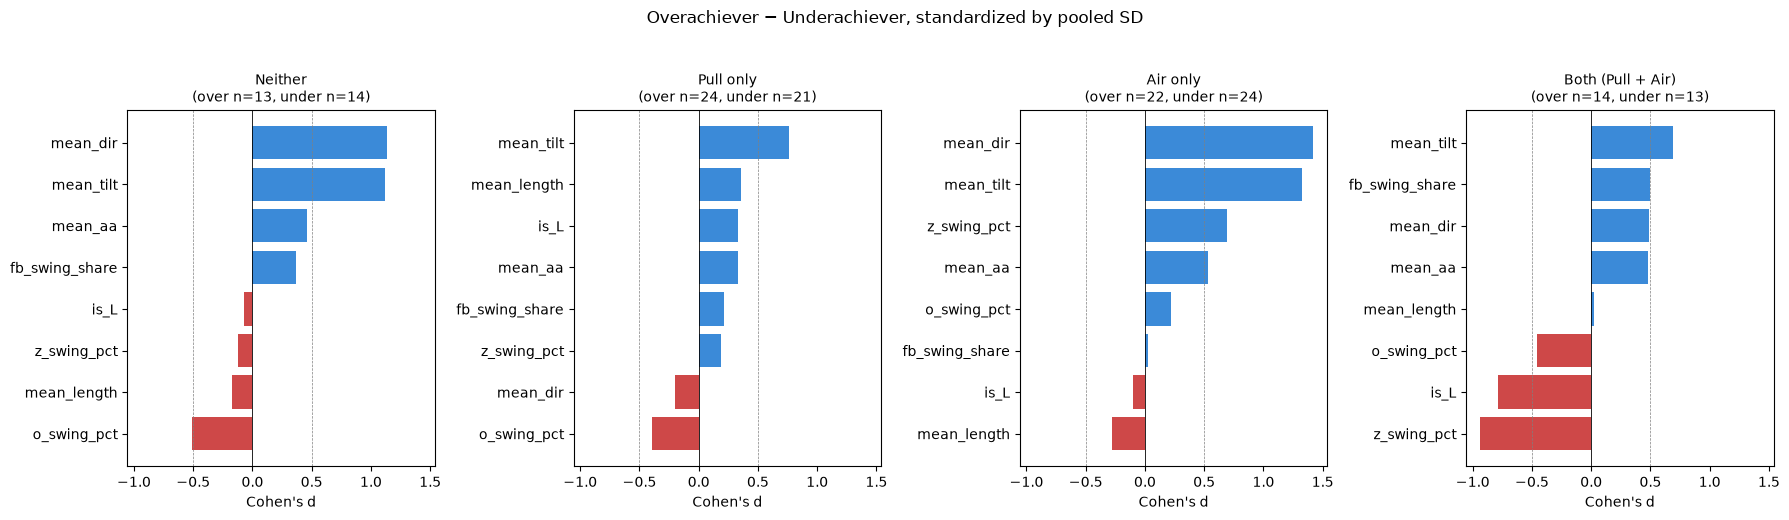

In [85]:
# ── Visual: standardized effect size by feature, one panel per quadrant ────
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharex=True)
for ax, q in zip(axes, QUAD_ORDER):
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        ax.set_title(f"{q}\n(insufficient n)")
        continue
    ds = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        d = (o.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0
        ds.append(d)
    ds = pd.Series(ds, index=ALL_FEATURES).sort_values()
    colors = ["#1976D2" if v > 0 else "#C62828" for v in ds.values]
    ax.barh(ds.index, ds.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.6)
    ax.axvline(0.5, color="gray", ls="--", lw=0.5)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
    ax.set_title(f"{q}\n(over n={len(over)}, under n={len(under)})", fontsize=10)
    ax.set_xlabel("Cohen's d")
plt.suptitle("Overachiever − Underachiever, standardized by pooled SD", y=1.03)
plt.tight_layout(); plt.show()

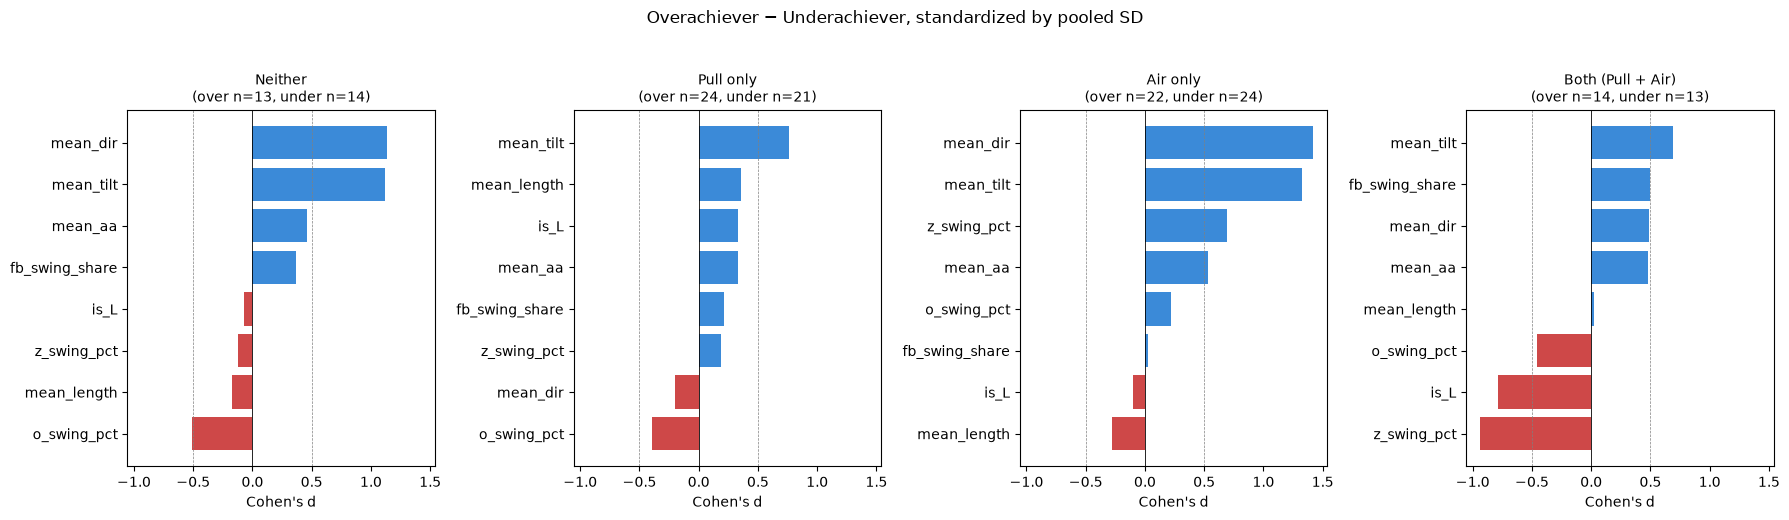

In [86]:
# ── Visual: standardized effect size by feature, one panel per quadrant ────
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharex=True)
for ax, q in zip(axes, QUAD_ORDER):
    sub_q = qd[qd["quadrant"] == q]
    over  = sub_q[sub_q["mismatch_type"] == "Overachiever"]
    under = sub_q[sub_q["mismatch_type"] == "Underachiever"]
    if len(over) < 5 or len(under) < 5:
        ax.set_title(f"{q}\n(insufficient n)")
        continue
    ds = []
    for f in ALL_FEATURES:
        o, u = over[f].dropna(), under[f].dropna()
        pooled_sd = np.sqrt(((len(o) - 1) * o.var() + (len(u) - 1) * u.var())
                            / (len(o) + len(u) - 2))
        d = (o.mean() - u.mean()) / pooled_sd if pooled_sd > 0 else 0
        ds.append(d)
    ds = pd.Series(ds, index=ALL_FEATURES).sort_values()
    colors = ["#1976D2" if v > 0 else "#C62828" for v in ds.values]
    ax.barh(ds.index, ds.values, color=colors, alpha=0.85)
    ax.axvline(0, color="black", lw=0.6)
    ax.axvline(0.5, color="gray", ls="--", lw=0.5)
    ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
    ax.set_title(f"{q}\n(over n={len(over)}, under n={len(under)})", fontsize=10)
    ax.set_xlabel("Cohen's d")
plt.suptitle("Overachiever − Underachiever, standardized by pooled SD", y=1.03)
plt.tight_layout(); plt.show()

In [87]:
# ── Batted-ball taxonomy: frequency and results by category ─────────────────
# Uses the same Pull/Air definitions as the rest of the thread, at the BBE level.

bb = bbe_full.copy() if "bbe_full" in dir() else cp.copy()
bb["_is_pull"] = (bb["spray_angle_norm"] > 0).astype(int)
bb["_is_air"]  = (bb["launch_angle"]    >= 10).astype(int)

def _bb_category(row):
    p, a = row["_is_pull"], row["_is_air"]
    if p and a:     return "Pull Air"
    if p and not a: return "Pull (non-Air)"
    if a and not p: return "Air (non-Pull)"
    return "Neither"

bb["bb_category"] = bb.apply(_bb_category, axis=1)
BB_ORDER = ["Pull Air", "Pull (non-Air)", "Air (non-Pull)", "Neither"]

print("── Batted-ball frequency by category ────────────────────────────────────")
freq = bb["bb_category"].value_counts(normalize=True).reindex(BB_ORDER)
print(freq.round(4).to_string())
print(f"\nTotal batted balls: {len(bb):,}")

── Batted-ball frequency by category ────────────────────────────────────
bb_category
Pull Air         0.2932
Pull (non-Air)   0.1105
Air (non-Pull)   0.2721
Neither          0.3242

Total batted balls: 289,704


In [88]:
# ── Batted-ball taxonomy: Pull / Center / Oppo split at ±15°, crossed with Air ─
bb = bbe_full.copy() if "bbe_full" in dir() else cp.copy()

PULL_CUTOFF = 15   # spray_angle_norm > +15 = Pull, < -15 = Oppo, between = Center

def _direction_zone(angle):
    if angle > PULL_CUTOFF:
        return "Oppo"     # was "Pull"
    elif angle < -PULL_CUTOFF:
        return "Pull"     # was "Oppo"
    else:
        return "Center"

bb["direction_zone"] = bb["spray_angle_norm"].apply(_direction_zone)
bb["_is_air"] = (bb["launch_angle"] >= 10).astype(int)

def _bb_category(row):
    zone, air = row["direction_zone"], row["_is_air"]
    if zone == "Pull"   and air: return "Pull Air"
    if zone == "Pull"   and not air: return "Pull (non-Air)"
    if zone == "Center" and air: return "Center Air"
    if zone == "Center" and not air: return "Center (non-Air)"
    if zone == "Oppo"   and air: return "Oppo Air"
    if zone == "Oppo"   and not air: return "Oppo (non-Air)"

bb["bb_category"] = bb.apply(_bb_category, axis=1)
BB_ORDER = ["Pull Air", "Pull (non-Air)", "Center Air", "Center (non-Air)",
           "Oppo Air", "Oppo (non-Air)"]

print("── Batted-ball frequency by category (Pull/Center/Oppo × Air) ──────────")
freq = bb["bb_category"].value_counts(normalize=True).reindex(BB_ORDER)
print(freq.round(4).to_string())
print(f"\nTotal batted balls: {len(bb):,}")

print("\n── Direction zone alone ──────────────────────────────────────────────")
print(bb["direction_zone"].value_counts(normalize=True).reindex(["Pull","Center","Oppo"]).round(4).to_string())

── Batted-ball frequency by category (Pull/Center/Oppo × Air) ──────────
bb_category
Pull Air           0.1810
Pull (non-Air)     0.2631
Center Air         0.1840
Center (non-Air)   0.1024
Oppo Air           0.2003
Oppo (non-Air)     0.0692

Total batted balls: 289,704

── Direction zone alone ──────────────────────────────────────────────
direction_zone
Pull     0.4441
Center   0.2863
Oppo     0.2695


In [89]:
# ── Results by category ──────────────────────────────────────────────────
HIT_EVENTS = {"single", "double", "triple", "home_run"}
OUT_EVENTS = {"field_out", "force_out", "grounded_into_double_play", "double_play",
             "fielders_choice_out", "sac_fly", "sac_bunt", "triple_play"}

bb_res = bb[bb["events"].notna()].copy()
bb_res["is_hit"]  = bb_res["events"].isin(HIT_EVENTS).astype(int)
bb_res["bases"]   = bb_res["events"].map({
    "single": 1, "double": 2, "triple": 3, "home_run": 4}).fillna(0)
bb_res["at_bat"]  = bb_res["events"].isin(HIT_EVENTS | OUT_EVENTS).astype(int)
bb_res["hard_hit"] = (bb_res["launch_speed"] >= 95).astype(int)

def _results_by_category(df, cats):
    rows = []
    for cat in cats:
        sub_c = df[df["bb_category"] == cat]
        n = len(sub_c)
        row = {"category": cat, "n": n, "share_of_BBE": n / len(df)}
        row["AVG"] = sub_c.loc[sub_c["at_bat"] == 1, "is_hit"].mean()
        row["SLG"] = sub_c.loc[sub_c["at_bat"] == 1, "bases"].mean()
        row["mean_exit_velo"] = sub_c["launch_speed"].mean()
        row["hard_hit_rate"]  = sub_c["hard_hit"].mean()
        if {"woba_value", "woba_denom"}.issubset(sub_c.columns):
            wd = sub_c.loc[sub_c["woba_denom"] > 0]
            row["wOBA"] = wd["woba_value"].sum() / wd["woba_denom"].sum() if len(wd) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

results_tbl = _results_by_category(bb_res, BB_ORDER)
print("── Results by batted-ball category ─────────────────────────────────────")
print(results_tbl.round(3).to_string(index=False))

── Results by batted-ball category ─────────────────────────────────────
        category     n  share_of_BBE    AVG    SLG  mean_exit_velo  hard_hit_rate   wOBA
        Pull Air 52439        0.1810 0.5210 1.1800         92.4960         0.5060 0.7090
  Pull (non-Air) 76232        0.2630 0.2100 0.2450         87.0090         0.3550 0.2210
      Center Air 53295        0.1840 0.3190 0.5490         91.1790         0.4560 0.3710
Center (non-Air) 29655        0.1020 0.3410 0.3520         88.2600         0.4390 0.3230
        Oppo Air 58038        0.2000 0.2560 0.4230         86.1220         0.2510 0.2920
  Oppo (non-Air) 20045        0.0690 0.3750 0.4130         82.8280         0.3470 0.3660


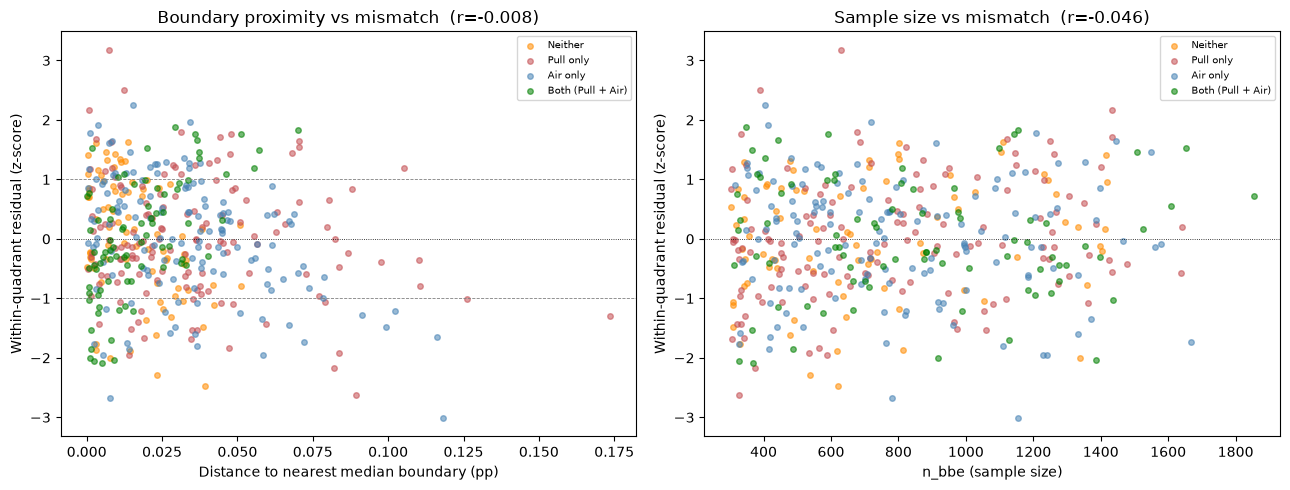

── Top 10 overachievers (highest positive residual) ────────────────────
 batter          quadrant  pull_air_pct  quad_mean  resid_z  n_bbe  min_boundary_dist
 664702         Pull only        0.3670     0.2910   3.1800    630             0.0070
 595909         Pull only        0.3510     0.2910   2.4970    388             0.0120
 571745          Air only        0.3290     0.2810   2.2460    404             0.0150
 681082         Pull only        0.3430     0.2910   2.1740   1432             0.0010
 669357          Air only        0.3230     0.2810   1.9600    718             0.0340
 693307          Air only        0.3220     0.2810   1.9090    413             0.0040
 678554 Both (Pull + Air)        0.3690     0.3240   1.8840    347             0.0290
 669257 Both (Pull + Air)        0.3680     0.3240   1.8330   1156             0.0700
 666134         Pull only        0.3340     0.2910   1.7910    677             0.0310
 643217          Air only        0.3190     0.2810   1.7790   1209 

In [67]:
# ── Visual: residual vs boundary distance and n_bbe ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for q in QUAD_ORDER:
    m = qd["quadrant"] == q
    axes[0].scatter(qd.loc[m, "min_boundary_dist"], qd.loc[m, "resid_z"],
                    s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[0].axhline(0, color="black", lw=0.6, ls=":")
axes[0].axhline(1, color="gray", lw=0.6, ls="--")
axes[0].axhline(-1, color="gray", lw=0.6, ls="--")
axes[0].set_xlabel("Distance to nearest median boundary (pp)")
axes[0].set_ylabel("Within-quadrant residual (z-score)")
axes[0].set_title(f"Boundary proximity vs mismatch  (r={r1:+.3f})")
axes[0].legend(fontsize=7)

for q in QUAD_ORDER:
    m = qd["quadrant"] == q
    axes[1].scatter(qd.loc[m, "n_bbe"], qd.loc[m, "resid_z"],
                    s=16, alpha=0.55, color=QUAD_COLORS[q], label=q)
axes[1].axhline(0, color="black", lw=0.6, ls=":")
axes[1].set_xlabel("n_bbe (sample size)")
axes[1].set_ylabel("Within-quadrant residual (z-score)")
axes[1].set_title(f"Sample size vs mismatch  (r={r2:+.3f})")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# Top mismatched hitters, for spot-checking
print("── Top 10 overachievers (highest positive residual) ────────────────────")
print(qd.sort_values("resid_z", ascending=False)
      [["batter", "quadrant", "pull_air_pct", "quad_mean", "resid_z", "n_bbe",
        "min_boundary_dist"]].head(10).round(3).to_string(index=False))

print("\n── Top 10 underachievers (most negative residual) ──────────────────────")
print(qd.sort_values("resid_z")
      [["batter", "quadrant", "pull_air_pct", "quad_mean", "resid_z", "n_bbe",
        "min_boundary_dist"]].head(10).round(3).to_string(index=False))

In [68]:
# ══ Rules-based classifier + effect-size-selected within-quadrant regression ══
# Stage 1: rules-based direction/tilt classifier (Gaussian likelihood, cross-validated).
# Stage 2: within each predicted bucket, regress on ONLY the features whose
#          standardized effect size (|Cohen's d|) cleared 0.5 in that quadrant's
#          over/underachiever analysis — a parsimonious, small-sample-safe
#          alternative to using all 7 features per bucket.

from scipy.stats import multivariate_normal

rb = batter_df.dropna(subset=ALL_FEATURES + ["pull_air_pct", "batter", "quadrant"]).copy()
groups_rb = rb["batter"].values
gkf_rb    = GroupKFold(n_splits=CV_FOLDS)
DIR_FEATS = ["mean_aa", "mean_dir"]

def _dir_group(q):
    if q == "Pull only": return "pull"
    if q == "Air only":  return "air"
    return "blend"
rb["dir_group"] = rb["quadrant"].map(_dir_group)

def _fit_rules(train_df):
    params = {}
    for g in ["pull", "air", "blend"]:
        x = train_df.loc[train_df["dir_group"] == g, DIR_FEATS].dropna().values.astype(np.float64)
        if len(x) < 2:
            x = train_df[DIR_FEATS].dropna().values.astype(np.float64)
        params[g] = {"mean": x.mean(axis=0),
                     "cov": np.cov(x.T) + np.eye(2) * 1e-3,
                     "prior": len(x) / len(train_df)}
    tilt_med = train_df.loc[train_df["dir_group"] == "blend", "mean_tilt"].median()
    return params, tilt_med

def _apply_rules(test_df, params, tilt_med):
    X_dir = test_df[DIR_FEATS].values
    liks = np.column_stack([
        multivariate_normal.logpdf(X_dir, mean=params[g]["mean"], cov=params[g]["cov"])
        + np.log(params[g]["prior"]) for g in ["pull", "air", "blend"]])
    pred_dir = np.array(["pull", "air", "blend"])[liks.argmax(axis=1)]
    tilt = test_df["mean_tilt"].values
    return np.where(pred_dir == "pull", "Pull only",
           np.where(pred_dir == "air",  "Air only",
           np.where(tilt >= tilt_med,   "Both (Pull + Air)", "Neither")))

pred_rules_rb = np.empty(len(rb), dtype=object)
for train_idx, test_idx in gkf_rb.split(rb, rb["quadrant"], groups_rb):
    params, tilt_med = _fit_rules(rb.iloc[train_idx])
    pred_rules_rb[test_idx] = _apply_rules(rb.iloc[test_idx], params, tilt_med)
rb["pred_quadrant_rules"] = pred_rules_rb

kap_rules_rb = cohen_kappa_score(rb["quadrant"], pred_rules_rb)
print(f"Stage 1 (rules-based) κ = {kap_rules_rb:.4f}")

Stage 1 (rules-based) κ = 0.4147


In [69]:
# ── Feature selection by |Cohen's d| >= 0.5, from your mismatch analysis ────
SELECTED_FEATS = {
    "Neither":            ["mean_dir", "mean_tilt"],                       # d = 1.14, 1.12
    "Pull only":          ["mean_tilt"],                                    # d = 0.76
    "Air only":           ["mean_dir", "mean_tilt", "z_swing_pct"],         # d = 1.42, 1.33, 0.69
    "Both (Pull + Air)":  ["z_swing_pct", "is_L", "mean_tilt"],             # d = -0.94, -0.78, 0.69
}
# Optional: rebuild this dict from your actual per-quadrant Cohen's d table
# instead of hardcoding, to stay tied to whatever the data shows:
#
# selected = {}
# for q in QUAD_ORDER:
#     d_tbl = <your standardized-difference table for q>
#     selected[q] = d_tbl.loc[d_tbl["Δ / SD (Cohen's d)"].abs() >= 0.5, "feature"].tolist()

def _two_stage(feat_map, model="ridge", min_n=15):
    pred = np.full(len(rb), np.nan)
    for q in QUAD_ORDER:
        mask  = rb["pred_quadrant_rules"].values == q
        sub_q = rb.loc[mask]
        feats = feat_map[q] if isinstance(feat_map, dict) else feat_map
        if len(sub_q) < min_n:
            pred[mask] = sub_q["pull_air_pct"].mean()
            continue
        n_folds = min(CV_FOLDS, sub_q["batter"].nunique())
        gkf_q = GroupKFold(n_splits=n_folds)
        pipe = Pipeline([("s", StandardScaler()),
                         ("m", Ridge(alpha=1.0) if model == "ridge" else LinearRegression())])
        pred[mask] = cross_val_predict(pipe, sub_q[feats].values, sub_q["pull_air_pct"].values,
                                       cv=gkf_q, groups=sub_q["batter"].values)
    return pred

pred_selected = _two_stage(SELECTED_FEATS, "ridge")
pred_allfeats = _two_stage(ALL_FEATURES,   "ridge")   # comparison: full feature set

sp_sel = spearmanr(pred_selected, rb["pull_air_pct"]).correlation
sp_all = spearmanr(pred_allfeats, rb["pull_air_pct"]).correlation
print(f"\n── Rules-based Stage 1 + Stage 2 comparison ─────────────────────────────")
print(f"  Effect-size-selected features (parsimonious):  Spearman = {sp_sel:+.4f}")
print(f"  All 7 features per bucket:                      Spearman = {sp_all:+.4f}")

print(f"\n── Per-true-quadrant Spearman ────────────────────────────────────────")
for q in QUAD_ORDER:
    m = rb["quadrant"].values == q
    if m.sum() < 10: continue
    sp_s = spearmanr(pred_selected[m], rb.loc[m, "pull_air_pct"]).correlation
    sp_a = spearmanr(pred_allfeats[m], rb.loc[m, "pull_air_pct"]).correlation
    print(f"  {q:<20}  selected={sp_s:+.3f}  all-features={sp_a:+.3f}  "
          f"Δ={sp_s-sp_a:+.3f}  n_feats_selected={len(SELECTED_FEATS[q])}")

NameError: name 'Ridge' is not defined

In [ ]:
# ── Load 2022–2025 Statcast parquets directly from the notebook's folder ────
from pathlib import Path

SEASONS_FULL = [2022, 2023, 2024, 2025]
NOTEBOOK_DIR = Path(".")   # same folder as the notebook

season_frames = []
for y in SEASONS_FULL:
    f = NOTEBOOK_DIR / f"statcast_{y}.parquet"
    if f.exists():
        df_y = pd.read_parquet(f)
        season_frames.append(df_y)
        print(f"Loaded {f.name}: {df_y.shape}")
    else:
        print(f"Missing: {f.name} — skipping {y}")

raw_all_full = pd.concat(season_frames, ignore_index=True)
print(f"\nraw_all_full: {raw_all_full.shape}")
print(f"Seasons present: {sorted(pd.to_datetime(raw_all_full['game_date']).dt.year.unique())}")

Loaded statcast_2022.parquet: (710210, 119)
Loaded statcast_2023.parquet: (720684, 119)
Loaded statcast_2024.parquet: (731904, 118)
Loaded statcast_2025.parquet: (734846, 118)

raw_all_full: (2897644, 119)
Seasons present: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [ ]:
# ── Rebuild the BBE frame across all seasons ────────────────────────────────
# pull_air only needs hc_x, hc_y, launch_angle, stand — all core fields, present
# in every Statcast season (unlike swing_path_tilt/attack_angle/bat_speed,
# which are bat-tracking-era only, 2024+). So this covers 2022-2025 fine.

bbe_full = raw_all_full[
    raw_all_full["description"].isin(["hit_into_play"]) &
    raw_all_full["launch_speed"].notna() &
    raw_all_full["launch_angle"].notna() &
    raw_all_full["hc_x"].notna() & raw_all_full["hc_y"].notna() &
    raw_all_full["stand"].notna() & raw_all_full["batter"].notna()
].copy()

bbe_full["spray_angle_norm"] = np.where(
    bbe_full["stand"] == "R",
     np.degrees(np.arctan((bbe_full["hc_x"] - 125.42) / (198.27 - bbe_full["hc_y"]))),
    -np.degrees(np.arctan((bbe_full["hc_x"] - 125.42) / (198.27 - bbe_full["hc_y"]))),
)
bbe_full["pull_air"] = ((bbe_full["spray_angle_norm"] > 0) &
                        (bbe_full["launch_angle"]    >= 10)).astype(int)
bbe_full["season"] = pd.to_datetime(bbe_full["game_date"]).dt.year

print(f"bbe_full: {bbe_full.shape}")
print(bbe_full["season"].value_counts().sort_index().to_string())

bbe_full: (500208, 122)
season
2022    123678
2023    123820
2024    125749
2025    126961


In [ ]:
MIN_BBE = 150

In [ ]:
# ── Season-level aggregation across all 4 years ─────────────────────────────
season_agg = (bbe_full.groupby(["batter", "season"])
             .agg(n_bbe=("pull_air", "count"), pull_air_pct=("pull_air", "mean"))
             .reset_index())
season_agg = season_agg[season_agg["n_bbe"] >= MIN_BBE]
print(f"Batter-seasons with ≥{MIN_BBE} BBE: {len(season_agg)}")
print(season_agg["season"].value_counts().sort_index().to_string())

# ── Build all consecutive-season pairs: 2022→23, 2023→24, 2024→25 ──────────
seasons_sorted = sorted(season_agg["season"].unique())
pairs = []
for s in seasons_sorted[:-1]:
    y1 = season_agg[season_agg["season"] == s][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y1"})
    y2 = season_agg[season_agg["season"] == s + 1][["batter", "pull_air_pct"]].rename(
        columns={"pull_air_pct": "pa_y2"})
    merged = y1.merge(y2, on="batter")
    merged["season_pair"] = f"{s}→{s+1}"
    pairs.append(merged)
stick = pd.concat(pairs, ignore_index=True)
print(f"\nTotal consecutive-season pairs: {len(stick)}")
print(stick["season_pair"].value_counts().to_string())

Batter-seasons with ≥150 BBE: 1348
season
2022    333
2023    342
2024    346
2025    327

Total consecutive-season pairs: 749
season_pair
2023→2024    260
2024→2025    245
2022→2023    244


In [ ]:
# ── Stickiness by pair and pooled ────────────────────────────────────────────
print("── Pull Air% year-over-year stickiness (all pairs, 2022-2025) ──────────")
for sp_name, g in stick.groupby("season_pair"):
    r = spearmanr(g["pa_y1"], g["pa_y2"]).correlation
    print(f"  {sp_name}: n={len(g)}, Spearman={r:.3f}")

r_pooled = spearmanr(stick["pa_y1"], stick["pa_y2"]).correlation
sb = 2 * r_pooled / (1 + r_pooled)
print(f"  Pooled across all pairs: n={len(stick)}, Spearman={r_pooled:.3f}")
print(f"  Spearman-Brown reliability estimate ≈ {sb:.3f}")

── Pull Air% year-over-year stickiness (all pairs, 2022-2025) ──────────
  2022→2023: n=244, Spearman=0.371
  2023→2024: n=260, Spearman=0.501
  2024→2025: n=245, Spearman=0.414
  Pooled across all pairs: n=749, Spearman=0.432
  Spearman-Brown reliability estimate ≈ 0.603


In [ ]:
# Check whether the 2023→24 spike is a sample-size or league-shift artifact
print("── Mean n_bbe and pull_air_pct by season ────────────────────────────────")
print(season_agg.groupby("season").agg(
    n_hitters=("batter", "count"),
    mean_n_bbe=("n_bbe", "mean"),
    mean_pull_air_pct=("pull_air_pct", "mean"),
    std_pull_air_pct=("pull_air_pct", "std")
).round(3).to_string())

── Mean n_bbe and pull_air_pct by season ────────────────────────────────
        n_hitters  mean_n_bbe  mean_pull_air_pct  std_pull_air_pct
season                                                            
2022          333    313.2250             0.2930            0.0370
2023          342    310.8570             0.2900            0.0360
2024          346    314.4860             0.2890            0.0380
2025          327    326.8350             0.2890            0.0370


── Pooled quintile transition matrix (row = Year N, col = Year N+1) ────
q_y2       Q1 (low)     Q2     Q3     Q4  Q5 (high)
q_y1                                               
Q1 (low)     0.3730 0.2000 0.2130 0.1130     0.1000
Q2           0.2670 0.2730 0.2130 0.1600     0.0870
Q3           0.1610 0.2750 0.2010 0.2480     0.1140
Q4           0.1400 0.1670 0.2400 0.2330     0.2200
Q5 (high)    0.0600 0.0870 0.1270 0.2470     0.4800

Average 'stayed in same quintile' rate: 31.2%  (vs 20% random)


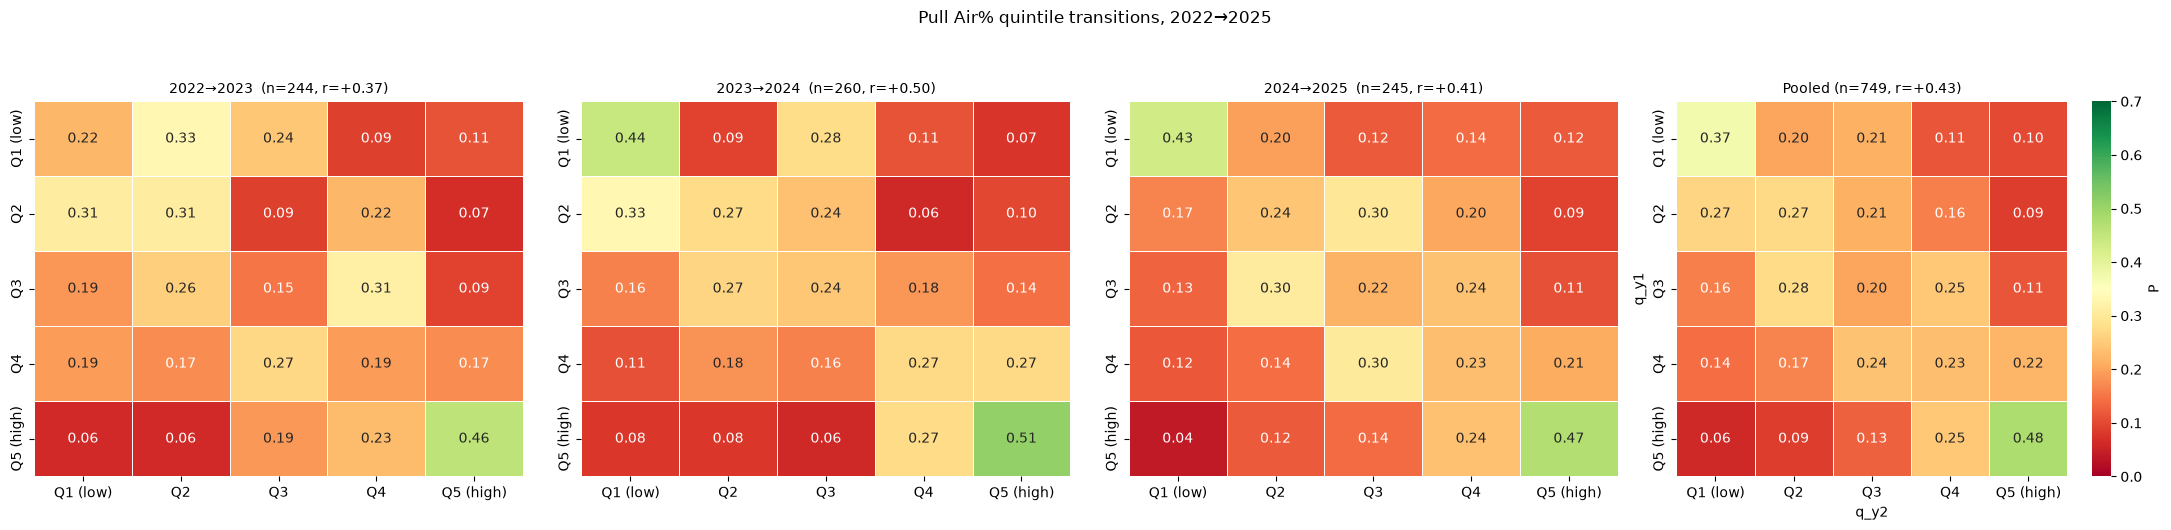

In [ ]:
# ── Quintile transition matrix — pooled and per-pair ────────────────────────
stick["q_y1"] = pd.qcut(stick["pa_y1"], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])
stick["q_y2"] = pd.qcut(stick["pa_y2"], 5, labels=["Q1 (low)", "Q2", "Q3", "Q4", "Q5 (high)"])

trans_pooled = pd.crosstab(stick["q_y1"], stick["q_y2"], normalize="index")
print("── Pooled quintile transition matrix (row = Year N, col = Year N+1) ────")
print(trans_pooled.round(3).to_string())
diag_pct = np.diag(trans_pooled.values).mean()
print(f"\nAverage 'stayed in same quintile' rate: {diag_pct:.1%}  (vs 20% random)")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (name, g) in zip(axes[:3], stick.groupby("season_pair")):
    t = pd.crosstab(g["q_y1"], g["q_y2"], normalize="index")
    sns.heatmap(t, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=0.7,
                linewidths=0.5, linecolor="white", ax=ax, cbar=False)
    r = spearmanr(g["pa_y1"], g["pa_y2"]).correlation
    ax.set_title(f"{name}  (n={len(g)}, r={r:+.2f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
sns.heatmap(trans_pooled, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=0.7,
            linewidths=0.5, linecolor="white", ax=axes[3], cbar_kws={"label": "P"})
axes[3].set_title(f"Pooled (n={len(stick)}, r={r_pooled:+.2f})", fontsize=10)
plt.suptitle("Pull Air% quintile transitions, 2022→2025", y=1.05)
plt.tight_layout(); plt.show()

In [ ]:
# ── Multi-season transition paths (3+ consecutive seasons) ──────────────────
# Assign each batter-season a quintile using THAT SEASON's own cutoffs
# (so "Q5" always means "top 20% of that specific year," not pooled).
season_agg["quintile"] = season_agg.groupby("season")["pull_air_pct"].transform(
    lambda s: pd.qcut(s, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]))

wide = season_agg.pivot(index="batter", columns="season", values="quintile")
seasons_sorted = sorted(season_agg["season"].unique())

def _longest_consecutive_run(row):
    present = [s for s in seasons_sorted if pd.notna(row[s])]
    if not present:
        return []
    runs, cur = [], [present[0]]
    for s in present[1:]:
        if s == cur[-1] + 1:
            cur.append(s)
        else:
            runs.append(cur)
            cur = [s]
    runs.append(cur)
    return max(runs, key=len)

wide["run"]     = wide.apply(_longest_consecutive_run, axis=1)
wide["run_len"] = wide["run"].apply(len)

multi = wide[wide["run_len"] >= 3].copy()
print(f"Batters with a 3+ consecutive-season run: {len(multi)}")
print(f"  Run-length distribution:")
print(multi["run_len"].value_counts().sort_index().to_string())

multi["path"] = multi.apply(lambda r: tuple(r[s] for s in r["run"]), axis=1)
path_counts = multi["path"].value_counts()

print(f"\n── Top 20 most common {seasons_sorted[0]}–{seasons_sorted[-1]} transition paths ──")
print(path_counts.head(20).to_string())

Batters with a 3+ consecutive-season run: 243
  Run-length distribution:
run_len
3     93
4    150

── Top 20 most common 2022–2025 transition paths ──
path
(Q5, Q5, Q5, Q5)    7
(Q5, Q5, Q5)        4
(Q5, Q4, Q5)        4
(Q2, Q1, Q1, Q1)    4
(Q1, Q2, Q2)        3
(Q4, Q4, Q5)        3
(Q1, Q1, Q1, Q1)    3
(Q4, Q2, Q3)        3
(Q1, Q1, Q1)        3
(Q4, Q1, Q3, Q4)    3
(Q4, Q3, Q2)        3
(Q4, Q1, Q3)        3
(Q1, Q3, Q2, Q3)    3
(Q4, Q2, Q4)        3
(Q4, Q1, Q1)        2
(Q1, Q2, Q1, Q1)    2
(Q2, Q3, Q2)        2
(Q4, Q2, Q1)        2
(Q3, Q2, Q1, Q3)    2
(Q2, Q4, Q4, Q3)    2


In [ ]:
# ── Categorize paths: stable, trending up, trending down, volatile ─────────
Q_NUM = {"Q1": 1, "Q2": 2, "Q3": 3, "Q4": 4, "Q5": 5}

def _classify_path(path):
    nums = [Q_NUM[q] for q in path]
    diffs = np.diff(nums)
    net = nums[-1] - nums[0]
    if all(d == 0 for d in diffs):
        return "Perfectly stable"
    if net >= 2:
        return "Trending up"
    if net <= -2:
        return "Trending down"
    if np.std(nums) <= 0.6:
        return "Stable (minor drift)"
    return "Volatile"

multi["path_type"] = multi["path"].apply(_classify_path)
print("── Path type distribution ───────────────────────────────────────────────")
print(multi["path_type"].value_counts().to_string())
print(f"\n(Out of {len(multi)} hitters with 3+ consecutive qualifying seasons)")

# Show the most common path within each category
print("\n── Most common path per category ────────────────────────────────────────")
for cat in multi["path_type"].unique():
    top = multi[multi["path_type"] == cat]["path"].value_counts().head(3)
    print(f"\n  {cat}:")
    for path, cnt in top.items():
        print(f"    {' → '.join(path)}   (n={cnt})")

── Path type distribution ───────────────────────────────────────────────
path_type
Volatile                73
Stable (minor drift)    64
Trending down           50
Trending up             37
Perfectly stable        19

(Out of 243 hitters with 3+ consecutive qualifying seasons)

── Most common path per category ────────────────────────────────────────

  Trending down:
    Q4 → Q3 → Q2   (n=3)
    Q4 → Q1 → Q1   (n=2)
    Q4 → Q2 → Q1   (n=2)

  Stable (minor drift):
    Q5 → Q4 → Q5   (n=4)
    Q2 → Q1 → Q1 → Q1   (n=4)
    Q1 → Q2 → Q2   (n=3)

  Volatile:
    Q4 → Q2 → Q3   (n=3)
    Q4 → Q1 → Q3 → Q4   (n=3)
    Q4 → Q1 → Q3   (n=3)

  Perfectly stable:
    Q5 → Q5 → Q5 → Q5   (n=7)
    Q5 → Q5 → Q5   (n=4)
    Q1 → Q1 → Q1 → Q1   (n=3)

  Trending up:
    Q1 → Q3 → Q2 → Q3   (n=3)
    Q3 → Q5 → Q5 → Q5   (n=2)
    Q1 → Q2 → Q1 → Q4   (n=2)


In [ ]:
# ── How well do Both / Neither line up with pull_air_pct quintiles Q5 / Q1? ─
qq = batter_df.dropna(subset=["quadrant", "pull_air_pct"]).copy()
qq["quintile"] = pd.qcut(qq["pull_air_pct"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])

# Full crosstab: row = quadrant, col = quintile, row-normalized
ct = pd.crosstab(qq["quadrant"], qq["quintile"], normalize="index").reindex(QUAD_ORDER)
print("── Quintile distribution WITHIN each quadrant ───────────────────────────")
print(ct.round(3).to_string())

# Column-normalized: within each quintile, what quadrant do hitters come from?
ct_col = pd.crosstab(qq["quadrant"], qq["quintile"], normalize="columns").reindex(QUAD_ORDER)
print("\n── Quadrant composition WITHIN each quintile ────────────────────────────")
print(ct_col.round(3).to_string())

── Quintile distribution WITHIN each quadrant ───────────────────────────
quintile              Q1     Q2     Q3     Q4     Q5
quadrant                                            
Neither           0.5850 0.2800 0.1340 0.0000 0.0000
Pull only         0.1080 0.2010 0.2590 0.2520 0.1800
Air only          0.1870 0.2370 0.2730 0.2590 0.0430
Both (Pull + Air) 0.0000 0.0490 0.0370 0.2070 0.7070

── Quadrant composition WITHIN each quintile ────────────────────────────
quintile              Q1     Q2     Q3     Q4     Q5
quadrant                                            
Neither           0.5390 0.2610 0.1250 0.0000 0.0000
Pull only         0.1690 0.3180 0.4090 0.3980 0.2810
Air only          0.2920 0.3750 0.4320 0.4090 0.0670
Both (Pull + Air) 0.0000 0.0450 0.0340 0.1930 0.6520


In [ ]:
# ── Both as a predictor of Q5, Neither as a predictor of Q1 ─────────────────
from sklearn.metrics import precision_score, recall_score, f1_score, cohen_kappa_score

is_both = (qq["quadrant"] == "Both (Pull + Air)").astype(int)
is_q5   = (qq["quintile"] == "Q5").astype(int)
is_neither = (qq["quadrant"] == "Neither").astype(int)
is_q1   = (qq["quintile"] == "Q1").astype(int)

print("── Both ↔ Q5 ─────────────────────────────────────────────────────────")
print(f"  precision (of hitters labeled Both, share that are Q5):  "
      f"{precision_score(is_q5, is_both):.3f}")
print(f"  recall    (of Q5 hitters, share labeled Both):            "
      f"{recall_score(is_q5, is_both):.3f}")
print(f"  F1:                                                        "
      f"{f1_score(is_q5, is_both):.3f}")

print("\n── Neither ↔ Q1 ──────────────────────────────────────────────────────")
print(f"  precision (of hitters labeled Neither, share that are Q1): "
      f"{precision_score(is_q1, is_neither):.3f}")
print(f"  recall    (of Q1 hitters, share labeled Neither):          "
      f"{recall_score(is_q1, is_neither):.3f}")
print(f"  F1:                                                          "
      f"{f1_score(is_q1, is_neither):.3f}")

# Combined "extreme" alignment: Both+Q5 union Neither+Q1 agreement rate
qq["extreme_label"] = np.where(is_both == 1, "Both",
                       np.where(is_neither == 1, "Neither", "Middle"))
qq["extreme_quintile"] = np.where(is_q5 == 1, "Q5",
                          np.where(is_q1 == 1, "Q1", "Middle"))
print("\n── Combined extreme-hitter alignment table ──────────────────────────────")
print(pd.crosstab(qq["extreme_label"], qq["extreme_quintile"]).to_string())

── Both ↔ Q5 ─────────────────────────────────────────────────────────
  precision (of hitters labeled Both, share that are Q5):  0.707
  recall    (of Q5 hitters, share labeled Both):            0.652
  F1:                                                        0.678

── Neither ↔ Q1 ──────────────────────────────────────────────────────
  precision (of hitters labeled Neither, share that are Q1): 0.585
  recall    (of Q1 hitters, share labeled Neither):          0.539
  F1:                                                          0.561

── Combined extreme-hitter alignment table ──────────────────────────────
extreme_quintile  Middle  Q1  Q5
extreme_label                   
Both                  24   0  58
Middle               206  41  31
Neither               34  48   0


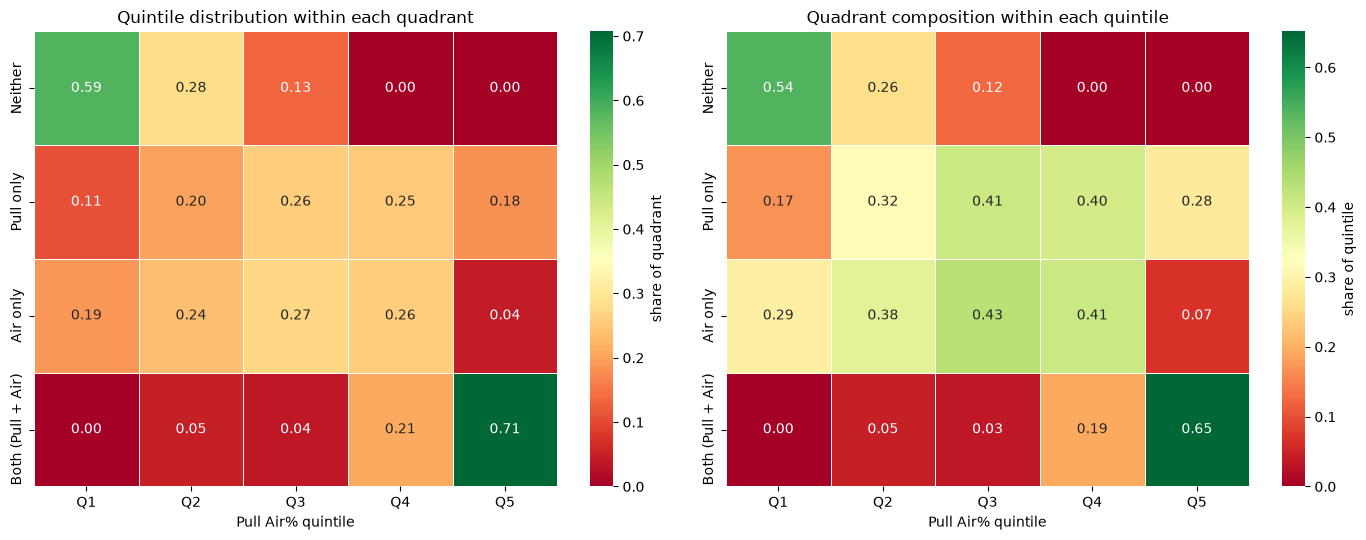

In [ ]:
# ── Visual: heatmap of quadrant × quintile ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(ct, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=ct.values.max(),
            linewidths=0.5, linecolor="white", ax=axes[0],
            cbar_kws={"label": "share of quadrant"})
axes[0].set_title("Quintile distribution within each quadrant")
axes[0].set_xlabel("Pull Air% quintile"); axes[0].set_ylabel("")

sns.heatmap(ct_col, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=ct_col.values.max(),
            linewidths=0.5, linecolor="white", ax=axes[1],
            cbar_kws={"label": "share of quintile"})
axes[1].set_title("Quadrant composition within each quintile")
axes[1].set_xlabel("Pull Air% quintile"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [ ]:
# ══ THE CHERRY ON TOP: what makes Both-hitter status STICK? ══
# Not "what is Both" (already answered — direction axis + tilt) but
# "among hitters who achieve Both, what separates the ones who sustain it
# from the ones who fall back to Pull only / Air only / Neither?"

# Requires: 'multi' (batters with 3+ consecutive season runs, from the
# stickiness work) and each season's quadrant label. Rebuild quadrant per
# season if not already present.
# ── Add pull_pct / air_ball_pct to season_agg (needed for per-season quadrant) ─
bbe_full["_is_pull"] = (bbe_full["spray_angle_norm"] > 0).astype(int)
bbe_full["_is_air"]  = (bbe_full["launch_angle"]    >= 10).astype(int)

season_agg = (bbe_full.groupby(["batter", "season"])
             .agg(n_bbe        = ("pull_air", "count"),
                  pull_air_pct = ("pull_air", "mean"),
                  pull_pct     = ("_is_pull", "mean"),
                  air_ball_pct = ("_is_air",  "mean"))
             .reset_index())
season_agg = season_agg[season_agg["n_bbe"] >= MIN_BBE]

print(f"season_agg rebuilt with marginals: {season_agg.shape}")
print(season_agg[["pull_air_pct", "pull_pct", "air_ball_pct"]].describe().round(3).to_string())
season_agg["is_pull_s"] = season_agg["pull_pct"]     >= season_agg["pull_pct"].median()
season_agg["is_air_s"]  = season_agg["air_ball_pct"] >= season_agg["air_ball_pct"].median()
def _label_s(r):
    p, a = r["is_pull_s"], r["is_air_s"]
    if p and a: return "Both"
    if p:       return "Pull only"
    if a:       return "Air only"
    return "Neither"
season_agg["quadrant_s"] = season_agg.apply(_label_s, axis=1)

wide_q = season_agg.pivot(index="batter", columns="season", values="quadrant_s")

def _longest_run(row):
    present = [s for s in seasons_sorted if pd.notna(row[s])]
    if not present: return []
    runs, cur = [], [present[0]]
    for s in present[1:]:
        if s == cur[-1] + 1: cur.append(s)
        else: runs.append(cur); cur = [s]
    runs.append(cur)
    return max(runs, key=len)

wide_q["run"] = wide_q.apply(_longest_run, axis=1)
wide_q["run_len"] = wide_q["run"].apply(len)
multi_q = wide_q[wide_q["run_len"] >= 2].copy()
multi_q["quad_path"] = multi_q.apply(lambda r: tuple(r[s] for s in r["run"]), axis=1)

# Define: ever-Both hitters, split into PERSISTENT (Both in 2+ seasons of their
# run) vs TRANSIENT (Both in exactly 1 season, then dropped out).
multi_q["n_both_seasons"] = multi_q["quad_path"].apply(lambda p: p.count("Both"))
ever_both = multi_q[multi_q["n_both_seasons"] >= 1].copy()
ever_both["persistent_both"] = ever_both["n_both_seasons"] >= 2

print(f"Hitters who were Both at least once: {len(ever_both)}")
print(f"  Persistent (Both 2+ seasons):  {ever_both['persistent_both'].sum()}")
print(f"  Transient  (Both exactly 1):    {(~ever_both['persistent_both']).sum()}")

season_agg rebuilt with marginals: (1348, 6)
       pull_air_pct  pull_pct  air_ball_pct
count     1348.0000 1348.0000     1348.0000
mean         0.2900    0.4080        0.5580
std          0.0370    0.0570        0.0690
min          0.1640    0.2370        0.3420
25%          0.2650    0.3680        0.5120
50%          0.2890    0.4060        0.5600
75%          0.3140    0.4450        0.6050
max          0.4090    0.5800        0.7790
Hitters who were Both at least once: 128
  Persistent (Both 2+ seasons):  59
  Transient  (Both exactly 1):    69


In [ ]:
# ── Compare their swing features — using the LAST season they were Both ─────
def _last_both_season(row):
    for s, q in zip(reversed(row["run"]), reversed(row["quad_path"])):
        if q == "Both":
            return s
    return None
ever_both["last_both_season"] = ever_both.apply(_last_both_season, axis=1)
ever_both_reset = ever_both.reset_index()

profile_rows = []
for _, row in ever_both_reset.iterrows():
    feat_row = season_agg[(season_agg["batter"] == row["batter"]) &
                          (season_agg["season"] == row["last_both_season"])]
    if len(feat_row) == 0: continue
    profile_rows.append({**feat_row.iloc[0].to_dict(),
                         "persistent_both": row["persistent_both"]})
profile = pd.DataFrame(profile_rows)

# Merge in swing-mechanics features from batter_df (or re-derive per-season if available)
profile = profile.merge(batter_df[["batter"] + [f for f in ALL_FEATURES if f != "is_L"] + ["stand"]]
                        .drop_duplicates("batter"), on="batter", how="left")
profile["is_L"] = (profile["stand"] == "L").astype(int)

print("── What separates PERSISTENT Both hitters from TRANSIENT ones ──────────")
rows = []
for f in ALL_FEATURES:
    p = profile.loc[profile["persistent_both"], f].dropna()
    t = profile.loc[~profile["persistent_both"], f].dropna()
    if len(p) < 5 or len(t) < 5:
        continue
    pooled_sd = np.sqrt(((len(p)-1)*p.var() + (len(t)-1)*t.var()) / (len(p)+len(t)-2))
    d = (p.mean() - t.mean()) / pooled_sd if pooled_sd > 0 else np.nan
    rows.append({"feature": f, "persistent_mean": p.mean(), "transient_mean": t.mean(),
                "Cohen_d": d})
result_tbl = pd.DataFrame(rows).sort_values("Cohen_d", key=lambda s: s.abs(), ascending=False)
print(result_tbl.round(3).to_string(index=False))

── What separates PERSISTENT Both hitters from TRANSIENT ones ──────────
       feature  persistent_mean  transient_mean  Cohen_d
     mean_tilt          33.8460         32.3270   0.3940
fb_swing_share           0.5710          0.5610   0.2300
   z_swing_pct           0.6790          0.6690   0.1970
      mean_dir          -0.1610         -0.6120   0.1890
          is_L           0.3560          0.2900   0.1410
   o_swing_pct           0.2900          0.2840   0.1100
   mean_length           7.2170          7.1850   0.0810
       mean_aa           8.4250          8.6300  -0.0740


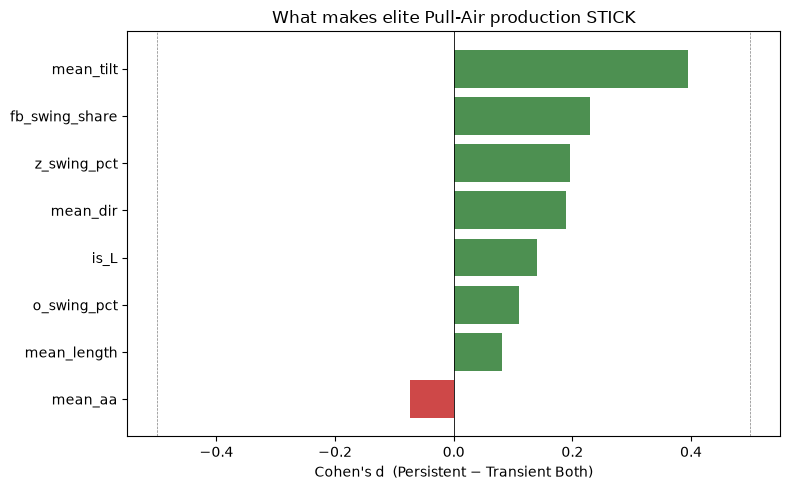

In [ ]:
# ── Visual ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
order = result_tbl.set_index("feature")["Cohen_d"].sort_values()
colors = ["#2E7D32" if v > 0 else "#C62828" for v in order.values]
ax.barh(order.index, order.values, color=colors, alpha=0.85)
ax.axvline(0, color="black", lw=0.6)
ax.axvline(0.5, color="gray", ls="--", lw=0.5); ax.axvline(-0.5, color="gray", ls="--", lw=0.5)
ax.set_xlabel("Cohen's d  (Persistent − Transient Both)")
ax.set_title("What makes elite Pull-Air production STICK")
plt.tight_layout(); plt.show()

## 5. Model Dataset

In [ ]:
need = ALL_FEATURES + ["quadrant", "pull_air_pct", "batter", "stand"]
sub = batter_df.dropna(subset=need).copy()
groups = sub["batter"].values
gkf    = GroupKFold(n_splits=CV_FOLDS)

print(f"Model dataset: n = {len(sub)} hitters")
print(f"Features: {ALL_FEATURES}")
print(f"Quadrant counts:")
print(sub["quadrant"].value_counts().reindex(QUAD_ORDER).to_string())


Model dataset: n = 442 hitters
Features: ['mean_tilt', 'mean_aa', 'mean_dir', 'z_swing_pct', 'o_swing_pct', 'fb_swing_share', 'mean_length', 'is_L']
Quadrant counts:
quadrant
Neither               82
Pull only            139
Air only             139
Both (Pull + Air)     82


In [ ]:
print(f"depth_in_c sample: {cp['depth_in_c'].head().tolist()}")
print(f"depth_in sample (should be small, e.g. -10 to +20 range): {cp['depth_in'].head().tolist()}")
print(f"Y_COL raw sample: {cp[Y_COL].head().tolist()}")

depth_in_c sample: [1.0735314911108205, 24.83801295204659, -5.128075902410856, 7.970770920566524, 3.6624495512386055]
depth_in sample (should be small, e.g. -10 to +20 range): [-33.882715616471486, -8.594203335590533, -34.78713487672731, -14.1321317793932, -26.24955097656552]
Y_COL raw sample: [33.882715616471486, 8.594203335590533, 34.78713487672731, 14.1321317793932, 26.24955097656552]


In [ ]:
# ── Depth: use raw Y_COL directly — no sign flip needed for this data ──────
cp["depth_in"]   = cp[Y_COL]                       # + = out in front, already correct
cp["depth_in_c"] = cp.groupby("batter")["depth_in"].transform(lambda s: s - s.mean())

# Rebuild mean_depth on batter_df from the corrected depth_in
depth_agg = (cp.groupby("batter")["depth_in"]
             .mean().rename("mean_depth").reset_index())
if "mean_depth" in batter_df.columns:
    batter_df = batter_df.drop(columns="mean_depth")
batter_df = batter_df.merge(depth_agg, on="batter", how="left")

print(f"mean_depth: {batter_df['mean_depth'].describe().round(2).to_string()}")

# Sanity checks
if "bat_speed" in cp.columns:
    r = cp[["depth_in", "bat_speed"]].dropna().corr().iloc[0, 1]
    print(f"\ncorr(depth_in, bat_speed) = {r:+.3f}   (expect + now)")

print(f"\nmean_depth by quadrant (expect Both/Air only highest, Neither lowest):")
print(batter_df.groupby("quadrant")["mean_depth"].mean().reindex(QUAD_ORDER).round(2).to_string())

mean_depth: count   442.0000
mean     29.9800
std       3.0400
min      20.8500
25%      27.8800
50%      29.9500
75%      32.1400
max      38.9500

corr(depth_in, bat_speed) = +0.241   (expect + now)

mean_depth by quadrant (expect Both/Air only highest, Neither lowest):
quadrant
Neither             29.8100
Pull only           29.1500
Air only            30.6900
Both (Pull + Air)   30.3600


In [ ]:
# Re-derive the optimal window from the CORRECTED pooled curve, not a guess
# Find where the pooled rate is within, say, 90% of its peak — a data-driven window
peak_rate = bin_rates.max()
peak_loc  = bin_centers[bin_rates.argmax()]
threshold = 0.90 * peak_rate
in_zone   = bin_centers[bin_rates >= threshold]
OPT_LO, OPT_HI = in_zone.min(), in_zone.max()

print(f"Corrected pooled curve peak: rate={peak_rate:.3f} at depth_in_c={peak_loc:+.2f}\"")
print(f"90%-of-peak window: [{OPT_LO:+.2f}, {OPT_HI:+.2f}]  (was hardcoded to [0, 10] before)")

# Rebuild depth_optimal_share with the corrected window
cp["_in_optimal"] = cp["depth_in_c"].between(OPT_LO, OPT_HI).astype(int)
optimal_share = (cp.groupby("batter")["_in_optimal"]
                 .mean().rename("depth_optimal_share").reset_index())

if "depth_optimal_share" in batter_df.columns:
    batter_df = batter_df.drop(columns="depth_optimal_share")
batter_df = batter_df.merge(optimal_share, on="batter", how="left")

r = spearmanr(batter_df["depth_optimal_share"], batter_df["pull_air_pct"]).correlation
print(f"Spearman(depth_optimal_share, pull_air_pct) = {r:+.3f}  (corrected window)")

Corrected pooled curve peak: rate=0.473 at depth_in_c=-6.52"
90%-of-peak window: [-7.70, -2.98]  (was hardcoded to [0, 10] before)
Spearman(depth_optimal_share, pull_air_pct) = +0.085  (corrected window)


## 6. Approach A — Multinomial Quadrant Classifier

Predicts the four quadrants jointly. Softmax naturally handles the mixture
cells without forcing them through two anti-correlated marginals.

In [ ]:
# RF multinomial (predictive)
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(
                        n_estimators=500, max_depth=10, min_samples_leaf=10,
                        class_weight="balanced", random_state=SEED, n_jobs=-1))])

proba_rf = cross_val_predict(pipe_rf, sub[ALL_FEATURES].values, sub["quadrant"].values,
                             cv=gkf, groups=groups, method="predict_proba")
pipe_rf.fit(sub[ALL_FEATURES].values, sub["quadrant"].values)
classes_rf = pipe_rf.named_steps["m"].classes_

# Align proba columns to QUAD_ORDER
class_to_col = {c: i for i, c in enumerate(classes_rf)}
proba_qd = np.column_stack([proba_rf[:, class_to_col[q]] for q in QUAD_ORDER])
pred_rf  = np.array(QUAD_ORDER)[proba_qd.argmax(axis=1)]
actual   = sub["quadrant"].values

acc_rf = accuracy_score(actual, pred_rf)
kap_rf = cohen_kappa_score(actual, pred_rf)

print(f"── Approach A (RF) ─────────────────────────────────────────────────────")
print(f"  Accuracy = {acc_rf:.4f}")
print(f"  Cohen κ  = {kap_rf:.4f}")
print(f"\n  Per-class one-vs-rest AUC:")
for q in QUAD_ORDER:
    y_oc = (actual == q).astype(int)
    p_oc = proba_qd[:, QUAD_ORDER.index(q)]
    print(f"    {q:<22} AUC = {roc_auc_score(y_oc, p_oc):.4f}")


── Approach A (RF) ─────────────────────────────────────────────────────
  Accuracy = 0.5882
  Cohen κ  = 0.4358

  Per-class one-vs-rest AUC:
    Neither                AUC = 0.7006
    Pull only              AUC = 0.8635
    Air only               AUC = 0.8863
    Both (Pull + Air)      AUC = 0.7471


── Per-quadrant metrics ───────────────────────────────────────────────
                   precision  recall  f1-score  support
Neither               0.3490  0.2680    0.3030  82.0000
Pull only             0.6840  0.6550    0.6690 139.0000
Air only              0.6620  0.7480    0.7030 139.0000
Both (Pull + Air)     0.4830  0.5240    0.5030  82.0000


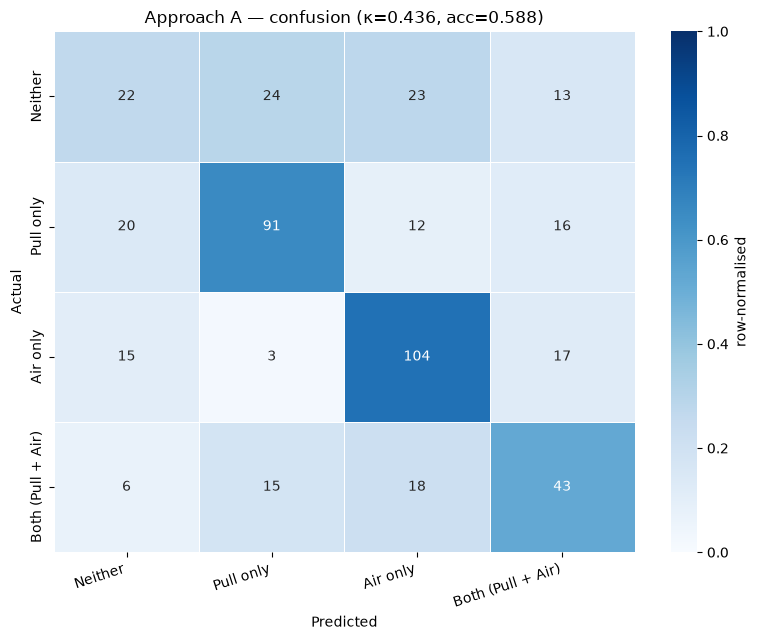

In [ ]:
# Per-category metrics + confusion matrix
rep_rf = pd.DataFrame(classification_report(actual, pred_rf, labels=QUAD_ORDER,
                      output_dict=True, zero_division=0)).T
print("── Per-quadrant metrics ───────────────────────────────────────────────")
print(rep_rf.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6.5))
cm  = confusion_matrix(actual, pred_rf, labels=QUAD_ORDER)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
            xticklabels=QUAD_ORDER, yticklabels=QUAD_ORDER,
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "row-normalised"})
ax.set_title(f"Approach A — confusion (κ={kap_rf:.3f}, acc={acc_rf:.3f})")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()


── Multinomial LR coefficients (standardised) ─────────────────────────
                Neither  Pull only  Air only  Both (Pull + Air)
mean_tilt       -0.5360    -0.0280   -0.0390             0.6040
mean_aa         -0.2010    -1.4850    1.6600             0.0260
mean_dir         0.4070     1.6780   -1.5430            -0.5420
z_swing_pct      0.0910    -0.1270    0.1390            -0.1030
o_swing_pct     -0.2580     0.1890   -0.1300             0.1990
fb_swing_share  -0.5890    -0.0840   -0.0080             0.6810
mean_length      0.1350    -0.0380   -0.1410             0.0440
is_L             0.2170    -0.4330    0.3770            -0.1600


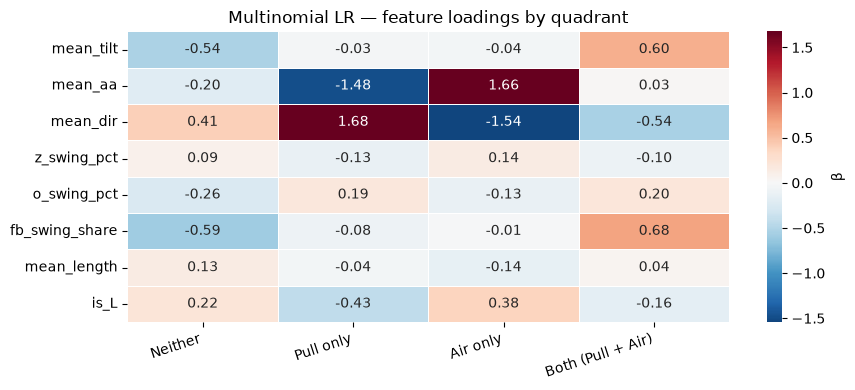


Read: each column is what makes a hitter that quadrant relative to the average.
Pull only and Air only should show opposite signs on mean_aa / mean_dir;
Both should look like Pull+Air mixed; Neither is the absence of both signals.


In [ ]:
# Multinomial LR for interpretable coefficients
pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(
                        multi_class="multinomial", solver="lbfgs",
                        max_iter=2000, C=0.5, class_weight="balanced",
                        random_state=SEED))])
pipe_lr.fit(sub[ALL_FEATURES].values, sub["quadrant"].values)
classes_lr = pipe_lr.named_steps["m"].classes_

coefs = pd.DataFrame(pipe_lr.named_steps["m"].coef_, index=classes_lr,
                     columns=ALL_FEATURES).reindex(QUAD_ORDER).T
print("── Multinomial LR coefficients (standardised) ─────────────────────────")
print(coefs.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(coefs, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"label": "β"})
ax.set_title("Multinomial LR — feature loadings by quadrant")
ax.set_xticklabels(QUAD_ORDER, rotation=18, ha="right")
plt.tight_layout(); plt.show()

print("\nRead: each column is what makes a hitter that quadrant relative to the average.")
print("Pull only and Air only should show opposite signs on mean_aa / mean_dir;")
print("Both should look like Pull+Air mixed; Neither is the absence of both signals.")


── Rules-based fitted parameters ──────────────────────────────────────
  pull   μ(aa)=+6.51  μ(dir)=+2.16  prior=0.314
  air    μ(aa)=+10.73  μ(dir)=-1.36  prior=0.314
  blend  μ(aa)=+8.18  μ(dir)=+0.00  prior=0.371
  Blend tilt threshold: 32.08

── Rules-based classifier (CV) ────────────────────────────────────────
  Accuracy = 0.5656
  Cohen κ  = 0.4147

── Per-quadrant metrics ───────────────────────────────────────────────
                   precision  recall  f1-score  support
Neither               0.3070  0.3780    0.3390  82.0000
Pull only             0.7440  0.6470    0.6920 139.0000
Air only              0.7560  0.6910    0.7220 139.0000
Both (Pull + Air)     0.3550  0.4020    0.3770  82.0000


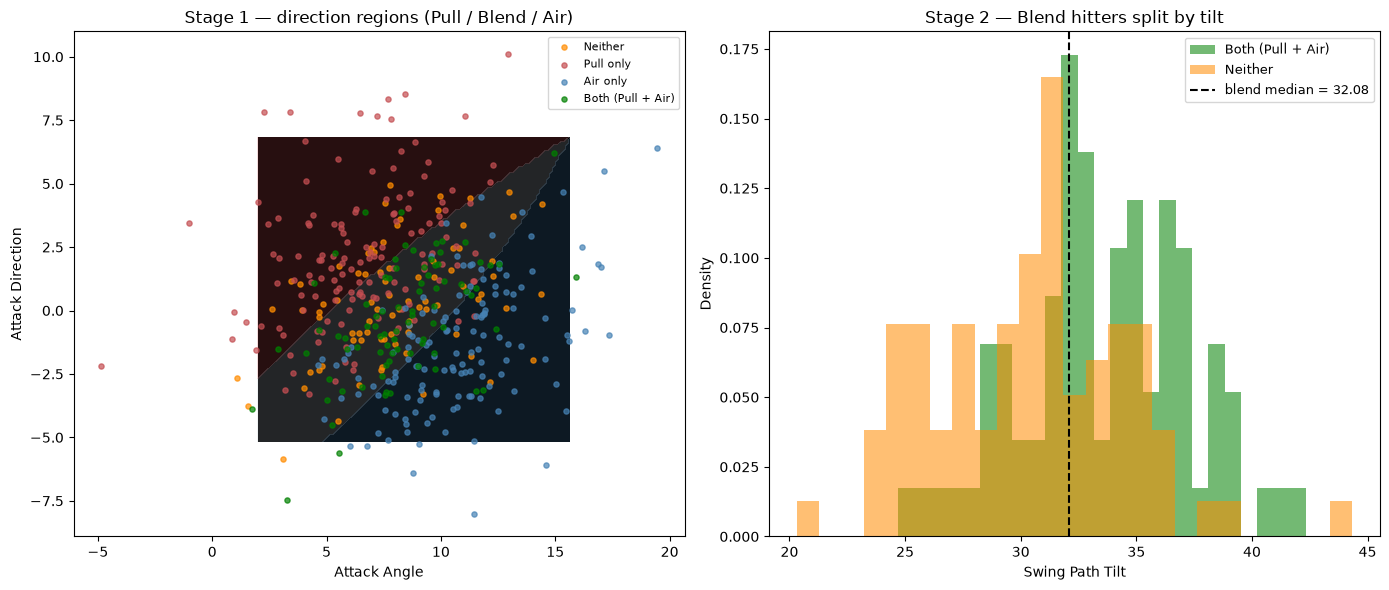

In [ ]:
# ── 6.5  Rules-based baseline: direction → intensity two-stage classifier ───
# Stage 1: assign to Pull / Blend / Air by likelihood under each direction group's
#          bivariate Gaussian fit on (mean_aa, mean_dir).
# Stage 2: Blend hitters split into Both / Neither by mean_tilt vs the blend median.
#
# Fit is in-sample (uses the full data's per-group distributions); we cross-validate
# the *predictions* so the comparison to Approach A is honest.
from scipy.stats import multivariate_normal

def _dir_group(q):
    if q == "Pull only": return "pull"
    if q == "Air only":  return "air"
    return "blend"                                         # Both + Neither
sub["dir_group"] = sub["quadrant"].map(_dir_group)

DIR_FEATS = ["mean_aa", "mean_dir"]

def _fit_rules(train_df):
    params = {}
    for g in ["pull", "air", "blend"]:
        x = train_df.loc[train_df["dir_group"] == g, DIR_FEATS].dropna().values.astype(np.float64)
        if len(x) < 2:
            x = train_df[DIR_FEATS].dropna().values.astype(np.float64)
        mean = x.mean(axis=0)
        cov  = np.cov(x.T) if len(x) >= 2 else np.eye(2)
        cov  = cov + np.eye(2) * 1e-3
        params[g] = {"mean": mean, "cov": cov,
                     "prior": max(1, len(x)) / len(train_df)}
    blend_tilt = train_df.loc[train_df["dir_group"] == "blend", "mean_tilt"].dropna()
    tilt_med = blend_tilt.median() if len(blend_tilt) else train_df["mean_tilt"].median()
    return params, tilt_med

def _apply_rules(test_df, params, tilt_med):
    X_dir = test_df[DIR_FEATS].values
    liks = np.column_stack([
        multivariate_normal.logpdf(X_dir, mean=params[g]["mean"], cov=params[g]["cov"])
        + np.log(params[g]["prior"])
        for g in ["pull", "air", "blend"]
    ])
    pred_dir = np.array(["pull", "air", "blend"])[liks.argmax(axis=1)]
    tilt = test_df["mean_tilt"].values
    return np.where(pred_dir == "pull", "Pull only",
           np.where(pred_dir == "air",  "Air only",
           np.where(tilt >= tilt_med,   "Both (Pull + Air)", "Neither")))

# Cross-validated rules-based predictions (same folds as Approach A)
pred_rules = np.empty(len(sub), dtype=object)
for train_idx, test_idx in gkf.split(sub, sub["quadrant"], groups):
    params, tilt_med = _fit_rules(sub.iloc[train_idx])
    pred_rules[test_idx] = _apply_rules(sub.iloc[test_idx], params, tilt_med)

# Fit once on full data too, for coefficient inspection
params_full, tilt_med_full = _fit_rules(sub)
print("── Rules-based fitted parameters ──────────────────────────────────────")
for g in ["pull", "air", "blend"]:
    p = params_full[g]
    print(f"  {g:5s}  μ(aa)={p['mean'][0]:+.2f}  μ(dir)={p['mean'][1]:+.2f}  "
          f"prior={p['prior']:.3f}")
print(f"  Blend tilt threshold: {tilt_med_full:.2f}")

# Metrics
kap_rules = cohen_kappa_score(actual, pred_rules)
acc_rules = accuracy_score(actual,   pred_rules)
print(f"\n── Rules-based classifier (CV) ────────────────────────────────────────")
print(f"  Accuracy = {acc_rules:.4f}")
print(f"  Cohen κ  = {kap_rules:.4f}")
print(f"\n── Per-quadrant metrics ───────────────────────────────────────────────")
print(pd.DataFrame(classification_report(actual, pred_rules, labels=QUAD_ORDER,
      output_dict=True, zero_division=0)).T.loc[
      QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

# Visual: the direction decision boundary drawn on the (aa, dir) plane
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) Direction likelihood map
aa_grid  = np.linspace(sub["mean_aa"].quantile(0.02),  sub["mean_aa"].quantile(0.98),  100)
dir_grid = np.linspace(sub["mean_dir"].quantile(0.02), sub["mean_dir"].quantile(0.98), 100)
AA, DD = np.meshgrid(aa_grid, dir_grid)
grid_pts = np.column_stack([AA.ravel(), DD.ravel()])
grid_liks = np.column_stack([
    multivariate_normal.logpdf(grid_pts, mean=params_full[g]["mean"], cov=params_full[g]["cov"])
    + np.log(params_full[g]["prior"])
    for g in ["pull", "air", "blend"]
])
grid_pred = np.array(["pull", "air", "blend"])[grid_liks.argmax(axis=1)]
region_colors = {"pull": "#c44e52", "air": "steelblue", "blend": "#B0BEC5"}
region_map = np.array([region_colors[g] for g in grid_pred]).reshape(AA.shape + (1,))
axes[0].imshow(np.zeros_like(AA)[..., None] * np.zeros(3), extent=[aa_grid[0], aa_grid[-1],
               dir_grid[0], dir_grid[-1]], aspect="auto", origin="lower")
# Simpler: contour of the argmax
for g_i, g in enumerate(["pull", "air", "blend"]):
    axes[0].contourf(AA, DD, (grid_pred.reshape(AA.shape) == g).astype(int),
                     levels=[0.5, 1.5], colors=[region_colors[g]], alpha=0.20)
for q in QUAD_ORDER:
    m = sub["quadrant"] == q
    axes[0].scatter(sub.loc[m, "mean_aa"], sub.loc[m, "mean_dir"],
                    s=14, alpha=0.7, color=QUAD_COLORS[q], label=q)
axes[0].set_xlabel("Attack Angle"); axes[0].set_ylabel("Attack Direction")
axes[0].set_title("Stage 1 — direction regions (Pull / Blend / Air)")
axes[0].legend(fontsize=8)

# (b) Tilt histogram for Blend hitters, with the split threshold
blend_mask = sub["dir_group"] == "blend"
for q in ["Both (Pull + Air)", "Neither"]:
    m = blend_mask & (sub["quadrant"] == q)
    axes[1].hist(sub.loc[m, "mean_tilt"], bins=25, alpha=0.55,
                 color=QUAD_COLORS[q], label=q, density=True)
axes[1].axvline(tilt_med_full, color="black", ls="--",
                label=f"blend median = {tilt_med_full:.2f}")
axes[1].set_xlabel("Swing Path Tilt"); axes[1].set_ylabel("Density")
axes[1].set_title("Stage 2 — Blend hitters split by tilt")
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 7. Approach B — Direct Joint Regression

Predicts `pull_air_pct` as a continuous score for ranking. Absorbs the
pull-air dependence inside the regressor's nonlinearity rather than fighting
two anti-correlated marginals.

── Approach B (RF regression) ─────────────────────────────────────────
  Spearman = +0.4254
  Pearson  = +0.4138
  RMSE     = 0.0281


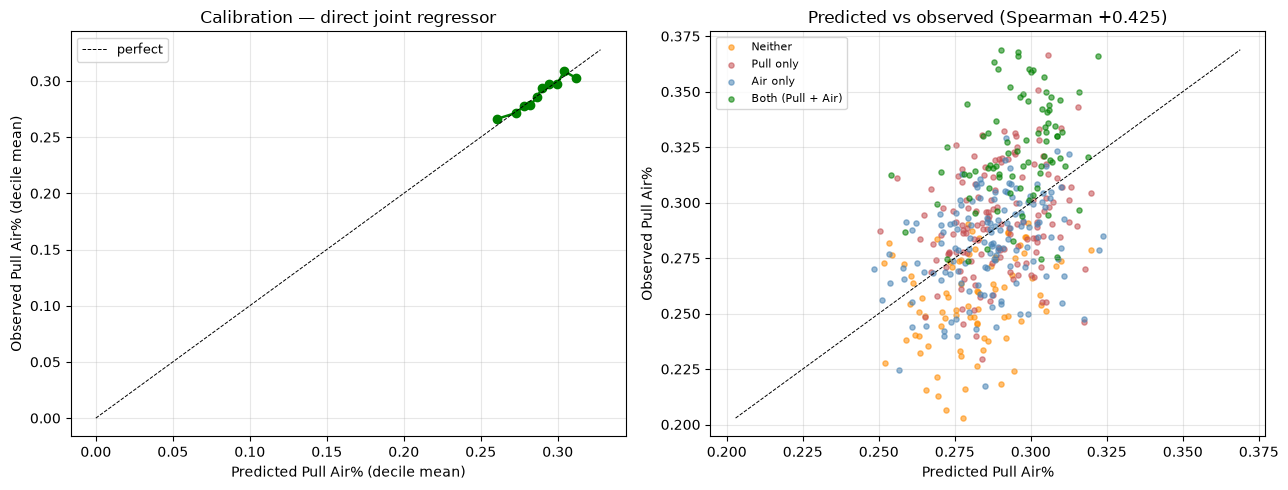

In [ ]:
pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         random_state=SEED, n_jobs=-1))])
pred_b = cross_val_predict(pipe_reg, sub[ALL_FEATURES].values,
                           sub["pull_air_pct"].values, cv=gkf, groups=groups)
y_pa = sub["pull_air_pct"].values

r_spear = spearmanr(pred_b, y_pa).correlation
r_pear  = pearsonr(pred_b,  y_pa)[0]
rmse    = float(np.sqrt(np.mean((pred_b - y_pa) ** 2)))
print(f"── Approach B (RF regression) ─────────────────────────────────────────")
print(f"  Spearman = {r_spear:+.4f}")
print(f"  Pearson  = {r_pear:+.4f}")
print(f"  RMSE     = {rmse:.4f}")

# Calibration + scatter
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = np.argsort(pred_b); bins = np.array_split(order, 10)
px = [pred_b[b].mean() for b in bins]
py = [y_pa[b].mean()   for b in bins]
axes[0].plot(px, py, "o-", color="green", lw=1.8, markersize=6)
lim = max(max(px), max(py)) * 1.05
axes[0].plot([0, lim], [0, lim], "k--", lw=0.7, label="perfect")
axes[0].set_xlabel("Predicted Pull Air% (decile mean)")
axes[0].set_ylabel("Observed Pull Air% (decile mean)")
axes[0].set_title("Calibration — direct joint regressor")
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

for q in QUAD_ORDER:
    m = actual == q
    axes[1].scatter(pred_b[m], y_pa[m], s=14, alpha=0.55,
                    color=QUAD_COLORS[q], label=q)
axes[1].plot([y_pa.min(), y_pa.max()], [y_pa.min(), y_pa.max()],
             "k--", lw=0.7)
axes[1].set_xlabel("Predicted Pull Air%"); axes[1].set_ylabel("Observed Pull Air%")
axes[1].set_title(f"Predicted vs observed (Spearman {r_spear:+.3f})")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 8. Comparison vs the Marginal-Cross Baseline

Confirms the new architecture beats the previous `P(pull) × P(air)` approach
on both ranking and quadrant classification.

In [ ]:
def _cv_proba_bin(feats, y, sub_df):
    pipe = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestClassifier(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         class_weight="balanced", random_state=SEED, n_jobs=-1))])
    return cross_val_predict(pipe, sub_df[feats].values, y,
                             cv=gkf, groups=sub_df["batter"].values,
                             method="predict_proba")[:, 1]

y_pull = sub["is_pull"].values
y_air  = sub["is_air"].values
P_pull = _cv_proba_bin(ALL_FEATURES, y_pull, sub)
P_air  = _cv_proba_bin(ALL_FEATURES, y_air,  sub)
joint_cross = P_pull * P_air

def _assign(pp, ap, tp, ta):
    return np.where((pp >= tp) & (ap >= ta), "Both (Pull + Air)",
           np.where((pp >= tp) & (ap <  ta), "Pull only",
           np.where((pp <  tp) & (ap >= ta), "Air only", "Neither")))

grid = np.linspace(0.30, 0.70, 21)
best = (-np.inf, 0.5, 0.5)
for tp in grid:
    for ta in grid:
        k = cohen_kappa_score(actual, _assign(P_pull, P_air, tp, ta))
        if k > best[0]: best = (k, tp, ta)
pred_cross = _assign(P_pull, P_air, best[1], best[2])

print(f"corr(P(pull), P(air)) = {np.corrcoef(P_pull, P_air)[0,1]:+.3f}   "
      f"(the entanglement that motivated the architecture switch)")
print(f"\n── Ranking pull_air_pct ───────────────────────────────────────────────")
print(f"  Approach B (direct regression) :  Spearman = "
      f"{spearmanr(pred_b, y_pa).correlation:+.4f}")
print(f"  Baseline P(pull)·P(air)        :  Spearman = "
      f"{spearmanr(joint_cross, y_pa).correlation:+.4f}")
print(f"\n── Quadrant classification ────────────────────────────────────────────")
print(f"  Approach A (multinomial argmax):  κ = {kap_rf:.4f}, acc = {acc_rf:.4f}")
print(f"  Baseline tuned corner          :  κ = "
      f"{cohen_kappa_score(actual, pred_cross):.4f}, "
      f"acc = {accuracy_score(actual, pred_cross):.4f}  "
      f"(at t_pull={best[1]:.2f}, t_air={best[2]:.2f})")

print(f"\n── Per-quadrant F1: A vs baseline ─────────────────────────────────────")
rep_a = pd.DataFrame(classification_report(actual, pred_rf, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
rep_b = pd.DataFrame(classification_report(actual, pred_cross, labels=QUAD_ORDER,
                     output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
print(pd.DataFrame({"Approach A": rep_a, "Baseline cross": rep_b,
                    "Δ": rep_a - rep_b}).round(3).to_string())


corr(P(pull), P(air)) = -0.747   (the entanglement that motivated the architecture switch)

── Ranking pull_air_pct ───────────────────────────────────────────────
  Approach B (direct regression) :  Spearman = +0.4254
  Baseline P(pull)·P(air)        :  Spearman = +0.3292

── Quadrant classification ────────────────────────────────────────────
  Approach A (multinomial argmax):  κ = 0.4358, acc = 0.5882
  Baseline tuned corner          :  κ = 0.4552, acc = 0.6063  (at t_pull=0.46, t_air=0.38)

── Per-quadrant F1: A vs baseline ─────────────────────────────────────
                   Approach A  Baseline cross       Δ
Neither                0.3030          0.1910  0.1120
Pull only              0.6690          0.7040 -0.0350
Air only               0.7030          0.7300 -0.0270
Both (Pull + Air)      0.5030          0.4670  0.0360


In [ ]:
# ── 8. Three-way comparison: rules baseline vs marginal cross vs Approach A ──
def _cv_proba_bin(feats, y, sub_df):
    pipe = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestClassifier(
                         n_estimators=500, max_depth=10, min_samples_leaf=10,
                         class_weight="balanced", random_state=SEED, n_jobs=-1))])
    return cross_val_predict(pipe, sub_df[feats].values, y,
                             cv=gkf, groups=sub_df["batter"].values,
                             method="predict_proba")[:, 1]

# Marginal cross baseline
y_pull = sub["is_pull"].values
y_air  = sub["is_air"].values
P_pull = _cv_proba_bin(ALL_FEATURES, y_pull, sub)
P_air  = _cv_proba_bin(ALL_FEATURES, y_air,  sub)
joint_cross = P_pull * P_air

def _assign(pp, ap, tp, ta):
    return np.where((pp >= tp) & (ap >= ta), "Both (Pull + Air)",
           np.where((pp >= tp) & (ap <  ta), "Pull only",
           np.where((pp <  tp) & (ap >= ta), "Air only", "Neither")))

grid = np.linspace(0.30, 0.70, 21)
best = (-np.inf, 0.5, 0.5)
for tp in grid:
    for ta in grid:
        k = cohen_kappa_score(actual, _assign(P_pull, P_air, tp, ta))
        if k > best[0]: best = (k, tp, ta)
pred_cross = _assign(P_pull, P_air, best[1], best[2])

# ── Ranking pull_air_pct ────────────────────────────────────────────────────
print(f"corr(P(pull), P(air)) = {np.corrcoef(P_pull, P_air)[0,1]:+.3f}")

print(f"\n── Ranking pull_air_pct ───────────────────────────────────────────────")
print(f"  Approach B (direct regression) :  Spearman = "
      f"{spearmanr(pred_b, y_pa).correlation:+.4f}")
print(f"  Baseline P(pull)·P(air)        :  Spearman = "
      f"{spearmanr(joint_cross, y_pa).correlation:+.4f}")

# ── Classification: three architectures ─────────────────────────────────────
print(f"\n── Quadrant classification ────────────────────────────────────────────")
print(f"  Rules-based (direction+tilt)   :  κ = {kap_rules:.4f}, acc = {acc_rules:.4f}")
print(f"  Baseline tuned corner          :  κ = "
      f"{cohen_kappa_score(actual, pred_cross):.4f}, "
      f"acc = {accuracy_score(actual, pred_cross):.4f}")
print(f"  Approach A (multinomial argmax):  κ = {kap_rf:.4f}, acc = {acc_rf:.4f}")

# Per-quadrant F1 for all three
f1_rules = pd.DataFrame(classification_report(actual, pred_rules, labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
f1_cross = pd.DataFrame(classification_report(actual, pred_cross, labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
f1_a     = pd.DataFrame(classification_report(actual, pred_rf,    labels=QUAD_ORDER,
                        output_dict=True, zero_division=0)).T.loc[QUAD_ORDER, "f1-score"]
comp = pd.DataFrame({"Rules": f1_rules, "Marginal cross": f1_cross, "Approach A": f1_a})
comp["A − Rules"]  = comp["Approach A"]   - comp["Rules"]
comp["A − Cross"]  = comp["Approach A"]   - comp["Marginal cross"]
print(f"\n── Per-quadrant F1: three architectures ───────────────────────────────")
print(comp.round(3).to_string())

# Visual: κ + accuracy bars
fig, ax = plt.subplots(figsize=(9, 4.5))
names  = ["Rules-based", "Marginal cross", "Approach A"]
kaps   = [kap_rules,      cohen_kappa_score(actual, pred_cross), kap_rf]
accs   = [acc_rules,      accuracy_score(actual, pred_cross),    acc_rf]
x = np.arange(len(names)); w = 0.38
ax.bar(x - w/2, kaps, w, color="#5C6BC0", label="κ")
ax.bar(x + w/2, accs, w, color="#26A69A", label="accuracy")
for i, (k, a) in enumerate(zip(kaps, accs)):
    ax.text(i - w/2, k + 0.01, f"{k:.3f}", ha="center", fontsize=9)
    ax.text(i + w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("Quadrant classification: three architectures")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 9. Final Deliverable

Quadrant label from Approach A + ranked Pull Air% score from Approach B —
the scouting view: *what kind of hitter* and *how good*.

In [ ]:
out = sub[["batter", "stand", "pull_pct", "air_ball_pct", "pull_air_pct",
           "quadrant"] + ALL_FEATURES].copy()
out["pred_quadrant"] = pred_rf
for q in QUAD_ORDER:
    out[f"P({q})"] = proba_qd[:, QUAD_ORDER.index(q)]
out["pred_pull_air_pct"] = pred_b
out["pull_air_pct_rank"] = pd.Series(pred_b).rank(pct=True).values

print("── Top 15 by predicted Pull Air% ──────────────────────────────────────")
top = out.sort_values("pred_pull_air_pct", ascending=False).head(15)
print(top[["batter", "stand", "quadrant", "pred_quadrant",
           "pull_air_pct", "pred_pull_air_pct", "pull_air_pct_rank"]
       + [f"P({q})" for q in QUAD_ORDER]].round(3).to_string(index=False))

print("\n── Disagreements (predicted quadrant ≠ actual) on top-ranked hitters ──")
disagree = out[(out["quadrant"] != out["pred_quadrant"])].sort_values(
    "pred_pull_air_pct", ascending=False).head(15)
print(disagree[["batter", "stand", "quadrant", "pred_quadrant",
                "pull_air_pct", "pred_pull_air_pct"]].round(3).to_string(index=False))
print("\nThese are development candidates — high predicted Pull Air% but not")
print("yet in the predicted quadrant. The mismatch flags hitters whose mechanics")
print("look like one quadrant but whose outcomes are tracking another.")


── Top 15 by predicted Pull Air% ──────────────────────────────────────
 batter stand          quadrant     pred_quadrant  pull_air_pct  pred_pull_air_pct  pull_air_pct_rank  P(Neither)  P(Pull only)  P(Air only)  P(Both (Pull + Air))
 624415     L          Air only Both (Pull + Air)        0.2850             0.3240             1.0000      0.1490        0.1460       0.1840                0.5200
 672695     L          Air only Both (Pull + Air)        0.2790             0.3220             0.9980      0.2160        0.2800       0.1020                0.4020
 545361     R Both (Pull + Air) Both (Pull + Air)        0.3660             0.3220             0.9950      0.1820        0.2280       0.1080                0.4820
 694384     L           Neither Both (Pull + Air)        0.2790             0.3200             0.9930      0.1960        0.2160       0.0780                0.5090
 663886     R         Pull only Both (Pull + Air)        0.3040             0.3200             0.9910      0.1610

## Summary

**Architecture**

- **Approach A** — multinomial RF over the four quadrants, with `is_L` and
  geometry features. Used for classification.
- **Approach B** — RF regression on `pull_air_pct`, same feature set. Used
  for ranking.
- The previous `is_pull` × `is_air` marginal-cross architecture was retired
  because the two marginals shared most of their feature signal and ended up
  near-mirror images of each other (corr ≈ −0.80), making their product a
  poor ranker.

**Other decisions preserved from the thread**

- Bat speed and contact depth dropped from modeling features — swing mechanics
  absorb their predictive signal because mechanics are upstream causes.
- Lateral contact: no mirror — the raw `intercept_*_x_inches` is already
  batter-relative in this Statcast vintage.
- Depth sign flipped at the source so `+ = out in front of plate`.
- Handedness `is_L` enters as a feature; the model uses it where it helps.
- Section 4 contact-plane diagnostics are descriptive evidence for the
  depth-by-quadrant development story, not model inputs.
